# Iran Job Market Analysis — Initial Data Analysis (IDA)

**Source:** JobVision job postings &nbsp;|&nbsp; **Stage:** exploratory analysis between data cleaning and feature engineering

This notebook audits the scraped postings, organises them into a sector taxonomy, and answers a set of
research questions about hiring demand, geography, skills, compensation, timing and competition. Its output is an
enriched, analysis-ready dataset for the matching and recommendation stages of the project.

### Contents
| # | Section | Core question |
|---|---------|---------------|
| 0 | Setup | Environment, configuration, data loading |
| 1 | Data audit | Is the data complete and internally consistent? |
| 2 | Job categorisation | How are ~70 raw categories mapped to analysable sectors? |
| 3 | Market overview | Where is demand, what kind of work, who can apply? |
| 4 | Companies and geography | Who hires, where, and how remote is it? |
| 5 | Skills and benefits | Which skills are requested and which co-occur? |
| 6 | Salary | What is paid, and which factors are associated with higher pay? |
| 7 | Hiring dynamics | How does activity evolve over time? |
| 8 | Competition | Which postings attract the most applicants? |
| 9 | Summary and export | Key findings, limitations, enriched dataset |

## Research Questions
1. **Demand** — Which roles, categories and industries post the most jobs?
2. **Geography** — How are jobs distributed across provinces and cities, and how common is remote work?
3. **Skills** — Which skills are requested most often, and which appear together?
4. **Compensation** — How do salaries vary with experience, seniority, sector and skills?
5. **Trends** — How does hiring activity change over time?
6. **Competition** — Which postings attract the most applicants?

## Data and Limitations
- **Single source.** Findings describe JobVision, not the whole Iranian labour market.
- **Keyword-driven sample.** Postings were collected with technology-oriented search keywords, so the sample leans towards
  software, data and adjacent roles. Non-technology sectors are *spill-over* from broad keywords, not a representative sample.
- **Self-selected salary disclosure.** Only about one third of postings publish pay. Section 6 tests how disclosers differ from non-disclosers.
- **Snapshot, not a panel.** The data contains postings that were *active at scrape time*. Time-based results (Section 7) are
  therefore affected by survivorship: long-lived postings are over-represented among older activation dates.
- **Associations, not causes.** All relationships reported here are observational.

## Statistical Toolkit
| Tool | Used for | How to read it |
|------|----------|----------------|
| **HHI** (0–10,000) | Market concentration | < 1,500 unconcentrated, 1,500–2,500 moderate, > 2,500 high (US DOJ convention) |
| **Effective N** (= 10,000 / HHI) | Concentration in plain units | Number of equally sized categories that would give the same HHI |
| **Gini / Lorenz curve** | Inequality across categories or postings | 0 = perfectly equal, 1 = fully concentrated |
| **Lift** | Over- or under-representation | > 1 more common than average, < 1 less common |
| **Cramér's V** | Strength of association between two categorical variables | 0.1 small, 0.3 medium, 0.5 large |
| **Mann–Whitney U + Cliff's δ** | Comparing two skewed distributions | δ = 2·P(A > B) − 1; \|δ\| < 0.15 negligible, < 0.33 small, < 0.47 medium |
| **Spearman ρ** | Monotonic association | Robust to outliers and non-linearity |
| **Wilson interval** | Uncertainty of a proportion | 95% interval; stable for small groups |
| **Robust OLS (HC3)** | Adjusted association with log salary | exp(β) − 1 is the approximate % difference |

## Setup

In [1]:
import re
import textwrap
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy import stats

In [2]:
from utils import (
    annotate_bars, concentration_metrics, cramers_v, detect_datetime_columns, effect_label,
    explode_items, general_inspect, get_info, group_rate, lorenz_curve, mannwhitney_report,
    normalize_persian, ols_hc3, pplot, rtl, rtl_labels, say, split_multi, wilson_ci,
)

In [3]:
INPUT_DIR = 'data/jobs_merge.csv'
OUTPUT_DIR = 'data/jobs_merged-processed'

In [4]:
SEED = 42
ALPHA = 0.05
MIN_GROUP = 50          # minimum postings for a group to appear in comparisons
MIN_SALARY_GROUP = 30   # minimum salary observations for a group to appear in salary comparisons
MIN_PROVINCE = 100      # minimum postings for a province to appear in regional comparisons
SALARY_UNIT = "million tomans"
TECH_COLOR, OTHER_COLOR = "#d62728", "#9aa5b1"

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
rng = np.random.default_rng(SEED)

### Load data

In [5]:
df = pd.read_csv(INPUT_DIR, low_memory=False)
general_inspect(df)

shape: (20386, 35)


,0,1,4000,16666,20384,20385
job_id,1396130,1401623,1427415,1562254,1573631,1578851
title,برنامه نویس Python,Senior Backend Engineer(Python/FastAPI)- Shoraka,طراح سایت (WordPress),کارشناس برنامه ریزی تولید,کارشناس فروش (کامپیوتر، شبکه و دوربین مداربسته),کارشناس مانیتورینگ - خانم
company,بارکس,بیمه بازار,پونه مدیا,گروه توسعه بن دا,فنی مهندسی هوش سیستم گیل,اسنپ مارکت
province,تهران,تهران,اصفهان,تهران,گیلان,تهران
city,تهران,تهران,اصفهان,صفادشت,رشت,تهران
salary_visible,False,False,False,False,True,False
experience_years,5,3,3,3,1,1
source,NaN,NaN,NaN,jobvision,jobvision,jobvision
scraped_at,NaN,NaN,NaN,2026-10-21,2026-10-24,2026-10-24
keyword,developer|linux|oracle|python|software developer|برنامه ...,backend|backend developer|cloud engineer|developer|devop...,css|developer|html|javascript|laravel|php|security|softw...,data analyst|تحلیلگر داده,کارشناس شبکه,کارشناس شبکه


,type,nan-count,nan-percent,unique
job_id,int64,0,0.00,20386
title,str,0,0.00,10545
company,str,0,0.00,8075
province,str,30,0.00,31
city,str,0,0.00,290
salary_visible,bool,0,0.00,2
experience_years,int64,0,0.00,18
source,str,12037,0.59,1
scraped_at,str,12037,0.59,3
keyword,str,0,0.00,4185


,count,mean,std,min,25%,50%,75%,max
job_id,"20,386.00","1,462,193.51","69,860.11","233,685.00","1,419,471.50","1,443,168.50","1,520,547.25","1,579,844.00"
experience_years,"20,386.00",2.90,1.96,0.00,2.00,3.00,4.00,21.00
salary_min,"6,720.00",39.54,23.08,3.00,25.00,35.00,45.00,320.00
salary_max,"6,720.00",55.29,32.58,4.00,35.00,45.00,60.00,500.00
required_age_min,"13,245.00",24.89,4.10,18.00,22.00,25.00,27.00,50.00
required_age_max,"13,393.00",38.44,5.23,20.00,35.00,38.00,40.00,50.00
application_count,"12,095.00",277.30,317.05,11.00,67.00,154.00,376.00,"4,675.00"


,count,unique,top,freq
title,20386,10545,نگهبان - آقا,249
company,20386,8075,فروشگاه های زنجیره ای افق کوروش,179
province,20356,31,تهران,13954
city,20386,290,تهران,12925
salary_visible,20386,2,False,13671
source,8349,1,jobvision,8349
scraped_at,8349,3,2026-10-21,7247
keyword,20386,4185,network|system administrator|ادمین شبکه|کارشناس شبکه,2431
description,20384,20044,"<p><span style=""color: rgba(0, 0, 0, 1)"">شرح شغل:</span>...",34
work_type,20384,4,Full Time,18183


In [6]:
DATE_COLS = detect_datetime_columns(df)
for col in DATE_COLS:
    df[col] = pd.to_datetime(df[col], format="mixed", errors="coerce", utc=True)

BOOL_COLS = [c for c in ["salary_visible", "internship", "remote", "urgent", "military"] if c in df.columns]
for col in BOOL_COLS:
    df[col] = df[col].map(lambda v: str(v).strip().lower() in {"true", "1", "1.0"})

for col in ["province", "city", "company"]:
    df[col] = normalize_persian(df[col])

Parsed 4 datetime columns (scraped_at, first_activation, activation, expire) and normalised Persian character variants in province, city and company names so that one entity is not counted under several spellings.



## Data Audit

#### Is the data complete and internally consistent enough to analyse?
Before interpreting anything, the dataset is checked for missingness, duplicated identifiers and logically impossible values.

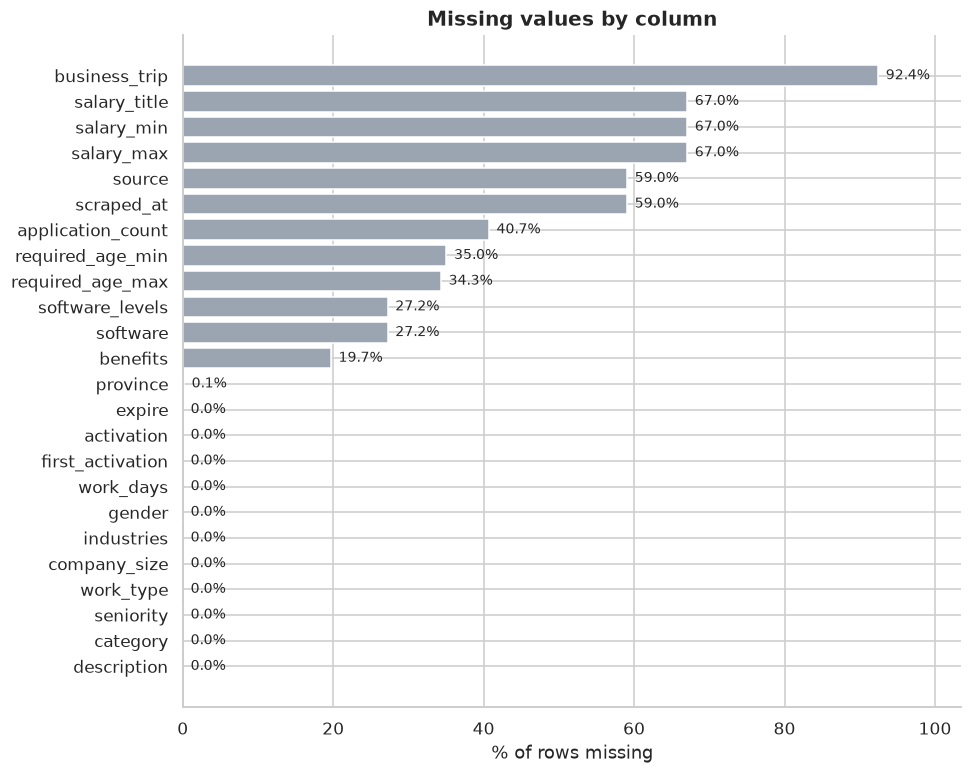

In [7]:
miss = get_info(df)["nan-percent"].mul(100).loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, max(3, 0.3 * len(miss))))
ax.barh(miss.index, miss.values, color=OTHER_COLOR)
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values by column")
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
plt.tight_layout()
plt.show()

In [8]:
audit = pd.Series({
    "Duplicate job_id": int(df["job_id"].duplicated().sum()),
    "Fully duplicated rows": int(df.duplicated().sum()),
    "salary_min > salary_max": int((df["salary_min"] > df["salary_max"]).sum()),
    "experience_years outside [0, 30]": int(((df["experience_years"] < 0) | (df["experience_years"] > 30)).sum()),
    "required_age_min > required_age_max": int((df["required_age_min"] > df["required_age_max"]).sum()),
    "activation after expire": int((df["activation"] > df["expire"]).sum()),
    "Postings without a detail record (no description)": int(df["description"].isna().sum()),
}, name="violations").to_frame()
audit["status"] = np.where(audit["violations"] == 0, "OK", "Review")
audit

,violations,status
Duplicate job_id,0,OK
Fully duplicated rows,0,OK
salary_min > salary_max,0,OK
"experience_years outside [0, 30]",0,OK
required_age_min > required_age_max,0,OK
activation after expire,0,OK
Postings without a detail record (no description),2,Review


In [9]:
if df["job_id"].duplicated().any():
    before = len(df)
    df = df.drop_duplicates(subset="job_id", keep="first").reset_index(drop=True)
    print(f"Dropped {before - len(df):,} duplicated job_id rows.")
n_post = len(df)

The analysis uses 20,386 unique postings. Rows lacking a detail record keep their list-level fields (title, company, location) and are excluded only from analyses that need the missing columns.



## Job Categorisation

JobVision assigns one or more of ~70 raw categories to each posting. For readable analysis, raw categories are mapped to
13 broader sectors. No posting is dropped: each keeps its full category list, receives one primary sector, and gets an
is_tech flag.

Because a posting may span several sectors, the primary sector is resolved with a fixed priority list (technology first).
This is a deliberate choice that favours the technology lens of the project; its effect is quantified below.

In [10]:
SECTOR_MAP = {
    # Technology
    "Network / DevOps / IT admin / Software Support and Deployment": "Technology",
    "IT - Software Development (Web,Moblie,…)": "Technology",
    "Data Science / AI": "Technology",
    "Software Quality Assurance": "Technology",
    "UI - UX Design": "Technology",

    # Sales & Marketing
    "Sales and Marketing - Specialist and Manager": "Sales & Marketing",
    "Sales and Marketing - Seller": "Sales & Marketing",
    "Digital Marketing / SEO": "Sales & Marketing",
    "Public Relations": "Sales & Marketing",
    "Medical Represantative": "Sales & Marketing",

    # Business & Management
    "Business Development And Analysis / Strategy / Planning": "Business & Management",
    "Product Manager / Product Owner": "Business & Management",
    "Executive Manager": "Business & Management",
    "CEO / Business Head / Factory Manager": "Business & Management",
    "Commercial Affairs / Trading": "Business & Management",
    "Purchasing / Procurement": "Business & Management",

    # Finance & Legal
    "Accounting / Finance": "Finance & Legal",
    "Financial Market Trader and Analyst": "Finance & Legal",
    "Insurance Management": "Finance & Legal",
    "Legal": "Finance & Legal",
    "Collecting Agent": "Finance & Legal",

    # Engineering & Industry
    "Industrial Engineering / Manufacturing / Operations / Project Management": "Engineering & Industry",
    "Engineering - Electrical": "Engineering & Industry",
    "Engineering - Mechanical & Aerospace": "Engineering & Industry",
    "Engineering - Civil": "Engineering & Industry",
    "Engineering - Architecture": "Engineering & Industry",
    "Engineering - Agriculture / Animal Science": "Engineering & Industry",
    "Engineering - Biomedical": "Engineering & Industry",
    "Chemical Engineering / Oil & Gas Engineering": "Engineering & Industry",
    "Mining Engineering & Geology": "Engineering & Industry",
    "Food Industry Engineering": "Engineering & Industry",
    "Metallurgy Engineering": "Engineering & Industry",
    "Energy Engineering / Nuclear Engineering": "Engineering & Industry",
    "Polymer Engineering": "Engineering & Industry",
    "Textile Engineering": "Engineering & Industry",
    "Safety / Security / Environment (HSE)": "Engineering & Industry",

    # Creative & Media
    "Graphic Designer / Motion Graphic Designer": "Creative & Media",
    "Translation / Content Provider": "Creative & Media",
    "Film & Cinema": "Creative & Media",
    "Photography": "Creative & Media",
    "Industrial Design": "Creative & Media",
    "Game Design": "Creative & Media",
    "Cloth Design / Jewelry Design": "Creative & Media",
    "Journalist": "Creative & Media",
    "Music and Sound Design": "Creative & Media",

    # Healthcare & Science
    "Pharmacy / Biochemistry / Chemistry": "Healthcare & Science",
    "Biology / Life Sciences / Laboratory Sciences": "Healthcare & Science",
    "Research": "Healthcare & Science",
    "Nursing": "Healthcare & Science",
    "Physician / Dentist / Vet": "Healthcare & Science",
    "Psychology / Counseling / Social": "Healthcare & Science",
    "Physical education / Nutrition": "Healthcare & Science",

    # Education
    "Education / Teaching": "Education",

    # Administration & HR
    "Human Resources": "Administration & HR",
    "Administration / Secretarial / Operator": "Administration & HR",

    # Customer Service & Retail
    "Customer Support / Account Management": "Customer Service & Retail",
    "Visitor and Cashier": "Customer Service & Retail",
    "Store executive": "Customer Service & Retail",

    # Services & Hospitality
    "Security Guard": "Services & Hospitality",
    "Barista / Waitor": "Services & Hospitality",
    "Chef": "Services & Hospitality",
    "Pastry Chef": "Services & Hospitality",
    "Tour guide / Attendant": "Services & Hospitality",
    "Aged & Child Care": "Services & Hospitality",

    # Logistics & Trades
    "Transport / Logistics / Warehousing": "Logistics & Trades",
    "Delivery / Driver": "Logistics & Trades",
    "Technician": "Logistics & Trades",
    "Labourer / Cleaner": "Logistics & Trades",
    "Tailor": "Logistics & Trades",

    # Other
    "Unknown": "Other",
}

# When a posting spans several sectors, the first sector in this list becomes its primary sector.
SECTOR_PRIORITY = [
    "Technology", "Engineering & Industry", "Healthcare & Science", "Finance & Legal",
    "Education", "Business & Management", "Sales & Marketing", "Creative & Media",
    "Administration & HR", "Customer Service & Retail", "Logistics & Trades",
    "Services & Hospitality", "Other",
]
assert set(SECTOR_MAP.values()) == set(SECTOR_PRIORITY), "SECTOR_MAP and SECTOR_PRIORITY are out of sync"
print(f"{len(SECTOR_MAP)} raw categories -> {len(SECTOR_PRIORITY)} sectors")

70 raw categories -> 13 sectors


In [11]:
cat_lists = split_multi(df["category"].fillna("Unknown")).apply(lambda xs: [x.strip() for x in xs])

# Fail loudly if a future scrape introduces a category that has not been mapped yet.
unmapped = sorted(set(cat_lists.explode()) - set(SECTOR_MAP))
assert not unmapped, f"Unmapped categories: {unmapped}"

df["categories"] = cat_lists
df["sectors"] = cat_lists.apply(lambda cs: sorted({SECTOR_MAP[c] for c in cs}, key=SECTOR_PRIORITY.index))
df["sector"] = df["sectors"].str[0]
df["n_sectors"] = df["sectors"].str.len()
df["is_tech"] = df["sector"].eq("Technology")

multi = df["n_sectors"].value_counts().sort_index()
multi_tbl = pd.DataFrame({"postings": multi, "share_%": multi / multi.sum() * 100})
multi_tbl.index.name = "sectors spanned"
multi_tbl

,postings,share_%
sectors spanned,,
1,17077,83.77
2,3269,16.04
3,40,0.20


In [12]:
tech_defs = pd.Series({
    "Technology is the only sector": (df["is_tech"] & df["n_sectors"].eq(1)).mean() * 100,
    "Technology is the primary sector (used in this notebook)": df["is_tech"].mean() * 100,
}, name="% of postings").to_frame()
tech_defs

,% of postings
Technology is the only sector,30.54
Technology is the primary sector (used in this notebook),32.80


16.2% of postings span more than one sector. Because technology has top priority, the technology share is 32.8% under the primary-sector rule versus 30.5% if only postings that are exclusively technology are counted. The headline technology share should be read as an upper bound; the gap is the cross-sector (hybrid) share of technology postings.

#### Label quality check
Keyword-based scraping and multi-label categories can mislabel postings. Two quick title-based audits estimate how often
the technology label disagrees with the job title.

In [13]:
NON_TECH_TITLE = r"فروش|بازاریاب|حسابدار|نگهبان|منشی|کارشناس منابع انسانی|sales|marketing|accountant"
TECH_TITLE = r"برنامه ?نویس|developer|devops|دواپس|python|java|react|data scien|machine learning|\bQA\b|\bIT\b"

tech_with_sales_title = df["is_tech"] & df["title"].str.contains(NON_TECH_TITLE, case=False, na=False, regex=True)
other_with_tech_title = ~df["is_tech"] & df["title"].str.contains(TECH_TITLE, case=False, na=False, regex=True)

label_audit = pd.DataFrame({
    "postings": [tech_with_sales_title.sum(), other_with_tech_title.sum()],
    "share_of_group_%": [tech_with_sales_title.sum() / df["is_tech"].sum() * 100,
                         other_with_tech_title.sum() / (~df["is_tech"]).sum() * 100],
}, index=["Technology postings with sales / admin keywords in title",
          "Non-technology postings with technology keywords in title"])
display(label_audit)
df.loc[tech_with_sales_title, ["title", "category"]].head(10)

,postings,share_of_group_%
Technology postings with sales / admin keywords in title,52,0.78
Non-technology postings with technology keywords in title,185,1.35


,title,category
487,پشتیبان فنی فروش - خانم,Network / DevOps / IT admin / Software Support and Deplo...
928,Back-End .NET (سامانه‌های After Sales),"IT - Software Development (Web,Moblie,…)"
958,Back-End .NET (سامانه‌های After Sales),"IT - Software Development (Web,Moblie,…)"
972,برنامه‌نویس Full-Stack - سیستم فروش سازمانی,"IT - Software Development (Web,Moblie,…)"
1403,کارشناس فروش و بازاریابی (نرم‌افزارهای سازمانی),"Sales and Marketing - Specialist and Manager,IT - Softwa..."
1461,کارشناس فروش (محصولات و نرم افزارهای امنیت شبکه و اطلاعات),Network / DevOps / IT admin / Software Support and Deplo...
4047,کارشناس توسعه‌دهنده پایانه‌های فروشگاهی (Embedded Linux ...,"IT - Software Development (Web,Moblie,…)"
4158,فروشنده (ابزارآلات اندازه‌گیری دقیق),"Sales and Marketing - Seller, Visitor and Cashier,IT - S..."
4349,کارشناس سایت و سامانه فروش - خانم,Network / DevOps / IT admin / Software Support and Deplo...
4376,کارشناس تست نرم‌افزار (QA) (سامانه‌های After Sales),Software Quality Assurance


In [14]:
worst = label_audit["share_of_group_%"].max()

The title-based mismatch rates are 0.8% and 1.4%. Both are small, and many technology hits are legitimate (for example after-sales systems developers or point-of-sale software), so the sector mapping is adequate for aggregate analysis. Individual titles should not be treated as ground truth for the matching stage.

## Market Overview

#### What does hiring demand look like, and how does technology differ from everything else?
- Which sectors dominate, and how large is technology relative to the rest?
- Is demand concentrated in a few sectors or spread evenly?
- Within technology, which raw categories are the largest?

In [15]:
sector_tbl = df["sector"].value_counts().rename("postings").to_frame()
sector_tbl["share_%"] = sector_tbl["postings"] / n_post * 100
sector_tbl["cumulative_%"] = sector_tbl["share_%"].cumsum()
sector_tbl.round(2)

,postings,share_%,cumulative_%
sector,,,
Technology,6686,32.80,32.80
Sales & Marketing,4656,22.84,55.64
Engineering & Industry,2964,14.54,70.18
Business & Management,1870,9.17,79.35
Finance & Legal,1006,4.93,84.28
Services & Hospitality,779,3.82,88.10
Creative & Media,757,3.71,91.82
Administration & HR,608,2.98,94.80
Logistics & Trades,459,2.25,97.05


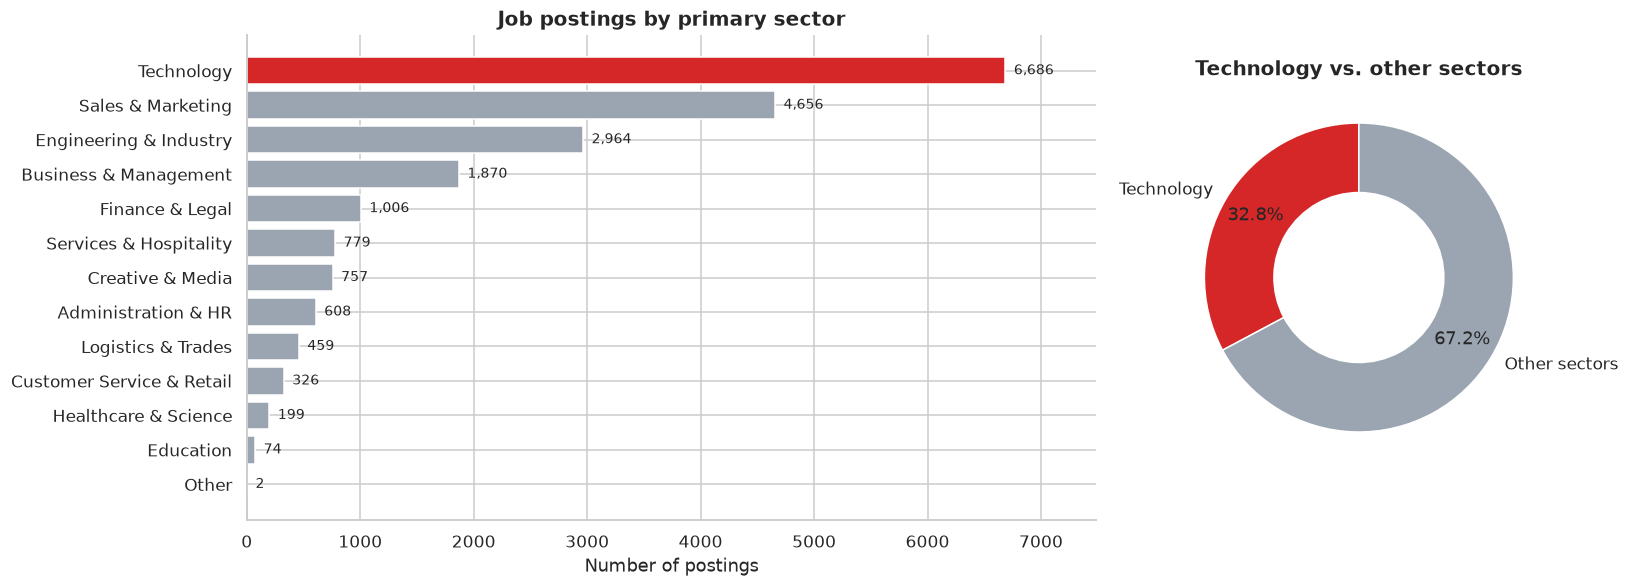

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2.2, 1]})

order = sector_tbl.index[::-1]
axes[0].barh(order, sector_tbl.loc[order, "postings"],
             color=[TECH_COLOR if s == "Technology" else OTHER_COLOR for s in order])
axes[0].margins(x=0.12)
annotate_bars(axes[0])
axes[0].set_title("Job postings by primary sector")
axes[0].set_xlabel("Number of postings")

n_tech = int(df["is_tech"].sum())
axes[1].pie([n_tech, n_post - n_tech], labels=["Technology", "Other sectors"], autopct="%1.1f%%", pctdistance=0.78,
            colors=[TECH_COLOR, OTHER_COLOR], startangle=90,
            wedgeprops={"edgecolor": "white", "width": 0.45})
axes[1].set_title("Technology vs. other sectors")
plt.tight_layout()
plt.show()

#### How concentrated is demand across sectors?
Concentration is measured with the Herfindahl–Hirschman Index (HHI), its *effective number* of equal-sized sectors, and the Gini
coefficient. The Lorenz curve shows the same information graphically: the further it bows below the diagonal, the more unequal demand is.

In [17]:
sector_conc = concentration_metrics(df["sector"].value_counts())
sector_conc.round(3).to_frame("sector demand")

,sector demand
categories,13.00
top1_%,32.80
top3_%,70.18
top5_%,84.28
hhi,"1,963.16"
hhi_norm,0.13
effective_n,5.09
gini,0.60


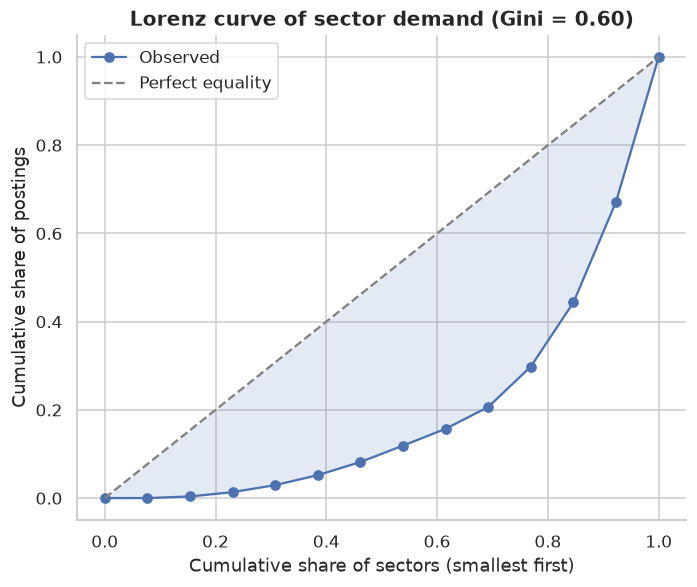

In [18]:
x, y = lorenz_curve(df["sector"].value_counts().values)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(x, y, marker="o", label="Observed")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect equality")
ax.fill_between(x, y, x, alpha=0.15)
ax.set(title=f"Lorenz curve of sector demand (Gini = {sector_conc['gini']:.2f})",
       xlabel="Cumulative share of sectors (smallest first)", ylabel="Cumulative share of postings")
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
bottom_half = float(np.interp(0.5, x, y))

Demand is moderately concentrated: HHI ≈ 1,963 (normalised 0.13), equivalent to about 5.1 equally sized sectors instead of 13. The top three sectors hold 70.2% of postings and the Gini coefficient is 0.60. The smallest half of sectors together account for only ~10% of postings. Technology alone represents 32.8%. The long tail of small sectors is expected from a keyword-driven sample.

#### Inside technology
A posting may carry several raw categories, so the shares below are *shares of technology postings that mention the category* and do not sum to 100%.

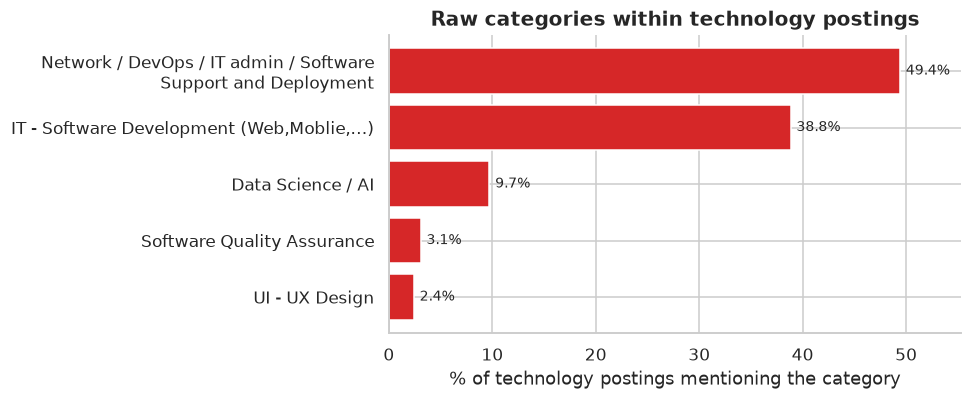

In [20]:
tech_df = df[df["is_tech"]]
tech_cats = (tech_df["categories"].explode().loc[lambda s: s.map(SECTOR_MAP).eq("Technology")].value_counts())
tech_cat_share = tech_cats / len(tech_df) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh([textwrap.fill(c, 42) for c in tech_cat_share.index[::-1]], tech_cat_share.values[::-1], color=TECH_COLOR)
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
ax.set(title="Raw categories within technology postings", xlabel="% of technology postings mentioning the category")
plt.tight_layout()
plt.show()

### What kind of employment do employers offer?
- Do full-time roles dominate, and do part-time and project-based roles concentrate in particular sectors?
- Does technology offer a different mix of work types than other sectors?

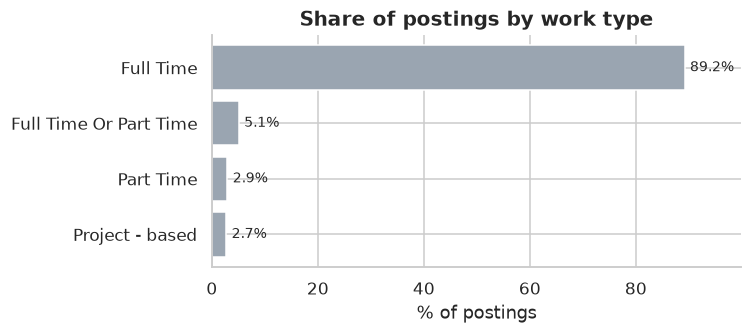

In [21]:
wt = df["work_type"].value_counts()
wt_share = wt / wt.sum() * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(wt_share.index[::-1], wt_share.values[::-1], color=OTHER_COLOR)
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
ax.set(title="Share of postings by work type", xlabel="% of postings")
plt.tight_layout()
plt.show()

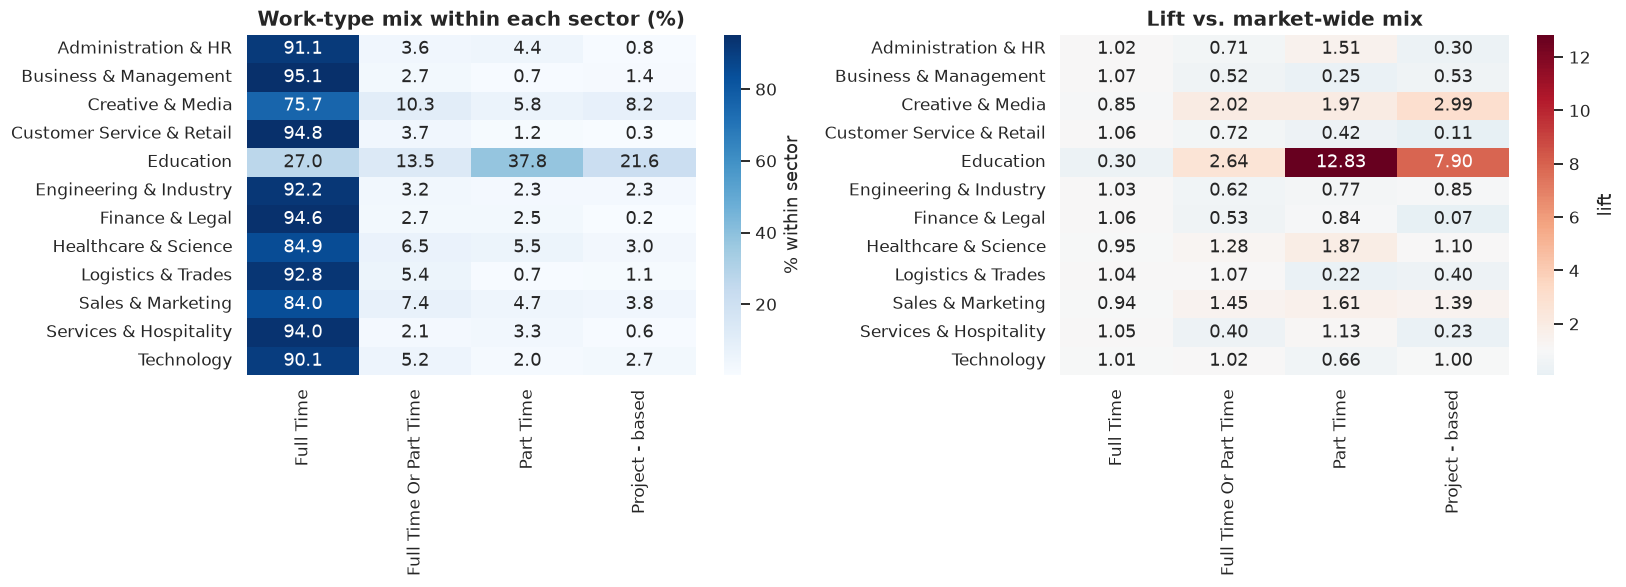

In [22]:
big_sectors = sector_tbl.index[sector_tbl["postings"] >= MIN_GROUP]
sub = df[df["sector"].isin(big_sectors)]
ct = pd.crosstab(sub["sector"], sub["work_type"])
ct_row = ct.div(ct.sum(axis=1), axis=0) * 100
lift = ct_row / (ct.sum(axis=0) / ct.to_numpy().sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(ct_row, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% within sector"}, ax=axes[0])
axes[0].set(title="Work-type mix within each sector (%)", xlabel="", ylabel="")
sns.heatmap(lift, annot=True, fmt=".2f", cmap="RdBu_r", center=1, cbar_kws={"label": "lift"}, ax=axes[1])
axes[1].set(title="Lift vs. market-wide mix", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

**Lift** compares a sector's work-type share with the market-wide share: `lift = P(work type | sector) / P(work type)`.
Lift above 1 means over-represented, below 1 under-represented, and exactly 1 means the sector looks like the market.
A chi-square test of independence (with Cramér's V as effect size) checks whether the pattern is more than noise.

In [23]:
wt_test = pd.Series(cramers_v(ct), name=f"sector x work_type (n={ct.to_numpy().sum():,})").to_frame()
display(wt_test)

cells = pd.DataFrame({"lift": lift.stack(), "postings": ct.stack()})
cells = cells[cells["postings"] >= 20].sort_values("lift", ascending=False)
display(cells.head(5).round(2))

,"sector x work_type (n=20,384)"
chi2,978.00
p_value,0.00
dof,33.00
cramers_v,0.12
cells_expected_lt5_%,6.25


lift  postings
sector            work_type                             
Education         Part Time              12.83        28
Creative & Media  Project - based         2.99        62
                  Full Time Or Part Time  2.02        78
                  Part Time               1.97        44
Sales & Marketing Part Time               1.61       221

Full Time accounts for 89.2% of postings; the remaining 10.8% are other arrangements. Work type and sector are statistically associated (χ² p = 4.1e-184) with Cramér's V = 0.12 (small effect). The strongest over-representation among cells with at least 20 postings is Part Time in Education (lift 12.83, n = 28). Cells with expected counts below 5 (6% of the table) make the chi-square p-value approximate; the effect size is the more reliable summary.

### How open is the market to newcomers?
- What share of postings accepts candidates with no experience, or up to one year?
- Does technology ask for more experience than other sectors?
- Which sectors are the most and least entry-friendly?
- Do the *seniority label* and the *experience requirement* tell the same story?

Postings without an experience value: 0


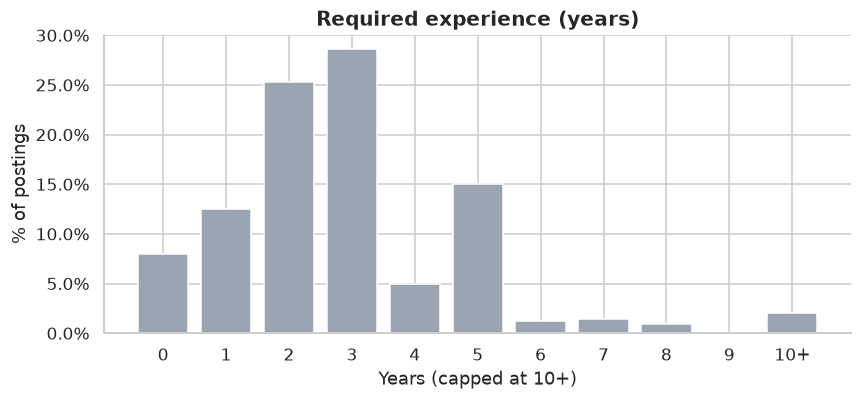

In [24]:
exp_df = df.dropna(subset=["experience_years"]).copy()
exp_df["entry_0"] = exp_df["experience_years"].eq(0)
exp_df["entry_le1"] = exp_df["experience_years"].le(1)
print(f"Postings without an experience value: {n_post - len(exp_df):,}")

capped = exp_df["experience_years"].clip(upper=10).astype(int)
dist = capped.value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([("10+" if i == 10 else str(i)) for i in dist.index], dist.values, color=OTHER_COLOR)
ax.set(title="Required experience (years)", ylabel="% of postings", xlabel="Years (capped at 10+)")
ax.yaxis.set_major_formatter(PercentFormatter())
plt.tight_layout()
plt.show()

In [25]:
a = exp_df.loc[exp_df["is_tech"], "experience_years"]
b = exp_df.loc[~exp_df["is_tech"], "experience_years"]
mw_exp = mannwhitney_report(a, b, labels=("tech", "other"))
mw_exp.to_frame("Mann-Whitney: experience required")

,Mann-Whitney: experience required
n_tech,"6,686.00"
n_other,"13,700.00"
median_tech,3.00
median_other,3.00
U,"44,826,672.50"
p_value,0.01
prob_superiority,0.49
cliffs_delta,-0.02


In [26]:
entry_0, entry_1 = exp_df["entry_0"].mean() * 100, exp_df["entry_le1"].mean() * 100

Only 8.0% of postings accept candidates with no experience and 20.5% accept up to one year. Median required experience is 3 years. Technology postings ask for a median of 3 years versus 3 elsewhere (p = 0.012). The effect size is negligible (Cliff's δ = -0.02; P(tech > other) = 0.49), so any difference is statistically detectable but practically small. With thousands of postings, small p-values alone do not imply a meaningful gap.

,n,entry_le1_pct,median_exp,mean_exp
sector,,,,
Education,74,33.80,2.00,2.30
Customer Service & Retail,326,30.10,2.00,2.50
Healthcare & Science,199,29.10,2.00,2.60
Services & Hospitality,779,27.50,2.00,2.40
Creative & Media,757,26.90,2.00,2.30
Sales & Marketing,4656,26.40,2.00,2.60
Logistics & Trades,459,26.40,3.00,2.70
Administration & HR,608,23.40,3.00,2.90
Technology,6686,19.50,3.00,2.80


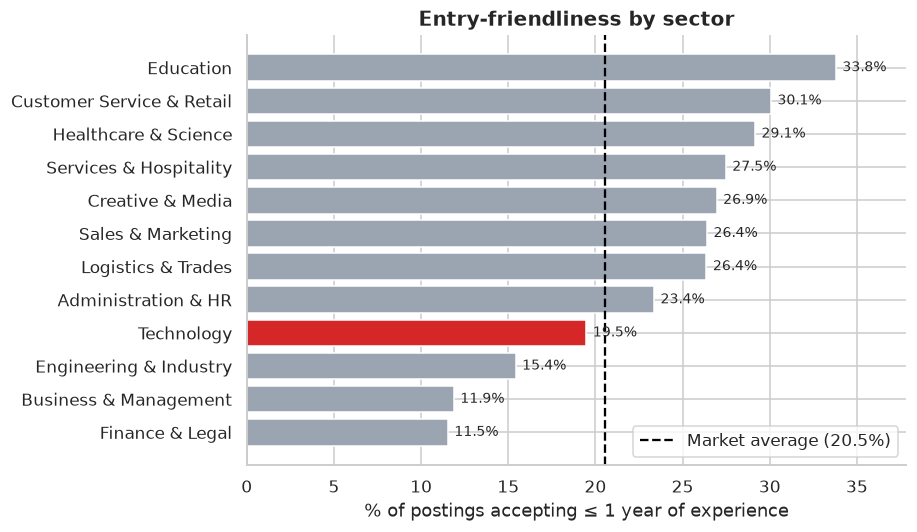

In [27]:
sector_exp = exp_df.groupby("sector").agg(
    n=("job_id", "size"),
    entry_le1_pct=("entry_le1", lambda s: s.mean() * 100),
    median_exp=("experience_years", "median"),
    mean_exp=("experience_years", "mean"),
).query("n >= @MIN_GROUP").sort_values("entry_le1_pct", ascending=False)
display(sector_exp.round(1))

fig, ax = plt.subplots(figsize=(8.5, 5))
vals = sector_exp["entry_le1_pct"].iloc[::-1]
ax.barh(vals.index, vals.values, color=[TECH_COLOR if s == "Technology" else OTHER_COLOR for s in vals.index])
ax.axvline(entry_1, color="black", ls="--", label=f"Market average ({entry_1:.1f}%)")
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
ax.set(title="Entry-friendliness by sector", xlabel="% of postings accepting ≤ 1 year of experience")
ax.legend()
plt.tight_layout()
plt.show()

#### Seniority label vs. experience requirement
If employers use the seniority label consistently, required experience should increase with it. The `Worker` level is excluded from the
rank correlation because it describes a type of labour rather than a rung on the managerial ladder.

,n,median_exp,mean_exp,entry_le1_pct
seniority,,,,
Internship,35,0.00,0.00,100.00
Employee,1886,1.00,1.54,51.11
Specialist,12183,2.00,2.33,23.92
Worker,322,2.00,2.17,36.96
Senior Specialist,3863,4.00,3.95,3.21
Manager,1833,5.00,5.44,1.53
Deputy / Senior Manager,206,6.00,6.77,1.94
CEO / Business Head,56,7.50,7.36,0.00


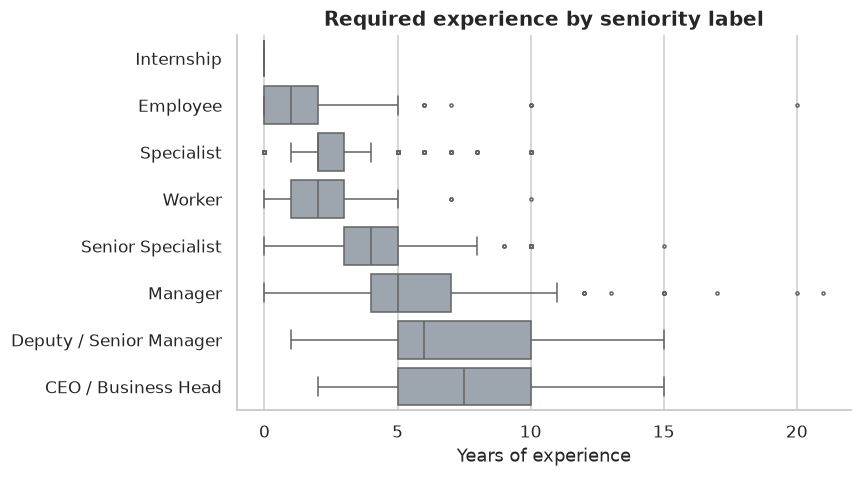

In [28]:
SENIORITY_RANK = {
    "Internship": 0, "Employee": 1, "Specialist": 2, "Senior Specialist": 3,
    "Manager": 4, "Deputy / Senior Manager": 5, "CEO / Business Head": 6,
}
sen_tbl = exp_df.groupby("seniority").agg(
    n=("job_id", "size"),
    median_exp=("experience_years", "median"),
    mean_exp=("experience_years", "mean"),
    entry_le1_pct=("entry_le1", lambda s: s.mean() * 100),
).sort_values("median_exp")
display(sen_tbl.round(2))

exp_df["seniority_rank"] = exp_df["seniority"].map(SENIORITY_RANK)
ranked = exp_df.dropna(subset=["seniority_rank"])
rho, p_rho = stats.spearmanr(ranked["seniority_rank"], ranked["experience_years"])

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=exp_df, x="experience_years", y="seniority", order=list(sen_tbl.index), color=OTHER_COLOR, fliersize=2, ax=ax)
ax.set(title="Required experience by seniority label", xlabel="Years of experience", ylabel="")
plt.tight_layout()
plt.show()

 Seniority and required experience are moderately aligned (Spearman ρ = 0.57, p = 0, n = 20,062). The boxes overlap between neighbouring levels, so the seniority label alone is an imperfect proxy for required experience; the matching stage should use both signals.

### How restrictive are employers in who they accept?
- How often do postings specify gender, military-service status or an age range?
- Are these restrictions more common in certain sectors?

*Gender preference* includes soft wording ("Preferred Men / Women"); *gender strict* only counts "Only Men / Only Women".

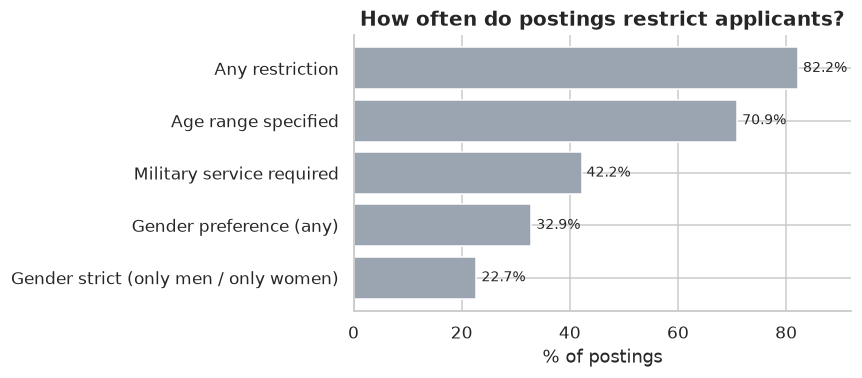

In [29]:
g = df["gender"].astype("string").str.strip()
df["gender_preference"] = (g.notna() & g.ne("Men / Women")).fillna(False).astype(bool)
df["gender_strict"] = g.isin(["Only Women", "Only Men"]).fillna(False).astype(bool)
df["military_req"] = df["military"]
df["age_restricted"] = df["required_age_min"].notna() | df["required_age_max"].notna()
df["any_restriction"] = df[["gender_preference", "military_req", "age_restricted"]].any(axis=1)

RESTRICTIONS = {
    "gender_preference": "Gender preference (any)",
    "gender_strict": "Gender strict (only men / only women)",
    "military_req": "Military service required",
    "age_restricted": "Age range specified",
    "any_restriction": "Any restriction",
}
rates = df[list(RESTRICTIONS)].mean().mul(100).rename(RESTRICTIONS).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(rates.index, rates.values, color=OTHER_COLOR)
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
ax.set(title="How often do postings restrict applicants?", xlabel="% of postings")
plt.tight_layout()
plt.show()

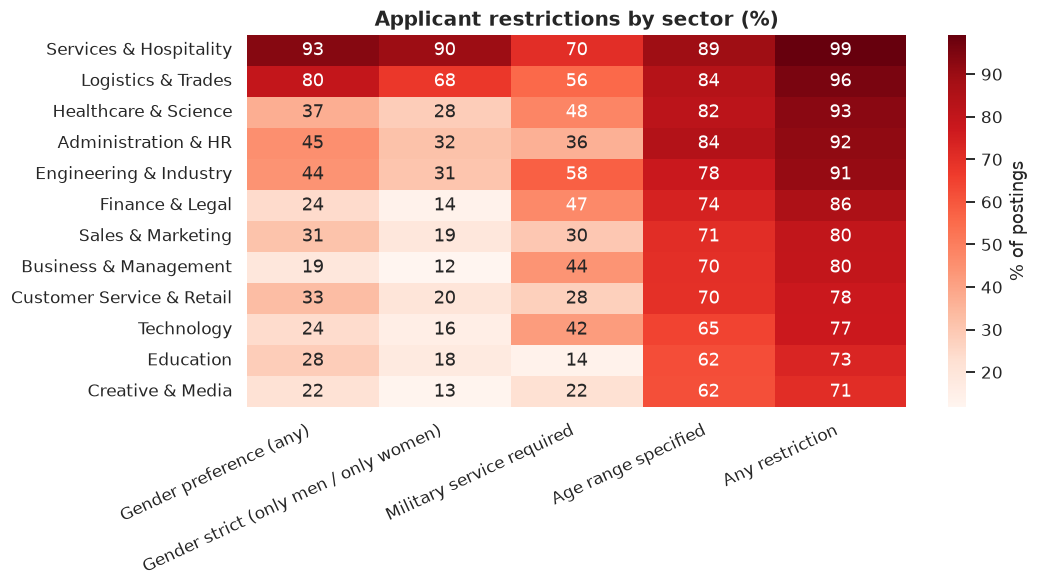

In [30]:
restr_by_sector = df[df["sector"].isin(big_sectors)].groupby("sector")[list(RESTRICTIONS)].mean().mul(100).rename(columns=RESTRICTIONS)
plt.figure(figsize=(10, 5.5))
sns.heatmap(restr_by_sector.sort_values("Any restriction", ascending=False), annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of postings"})
plt.title("Applicant restrictions by sector (%)")
plt.ylabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [31]:
men_only, women_only = int(g.eq("Only Men").sum()), int(g.eq("Only Women").sum())
single = rates.drop(["Any restriction", "Gender strict (only men / only women)"]).sort_values(ascending=False)

82.2% of postings carry at least one restriction. The most common is age range specified (70.9%), followed by military service required (42.2%). Strict gender requirements appear in 22.7% of postings, with 2.8 male-only postings for every female-only posting. The heatmap shows which sectors are most exclusionary; the military-service flag is only relevant to male candidates, so it is not a like-for-like restriction and mainly signals a male-oriented hiring pool.

## Companies and Geography

#### Who is hiring and where? Is the market concentrated in a few employers and a few places?
- Is hiring dominated by a handful of companies or spread across many?
- What share of postings do the top 10, 50 and 100 companies account for?
- What are the dominant company sizes and industries?

In [32]:
comp_counts = df["company"].value_counts()
comp_shares = comp_counts / comp_counts.sum() * 100
comp_conc = concentration_metrics(comp_counts)
singleton_share = (comp_counts == 1).mean() * 100

topk = pd.DataFrame([{
    "top_k": k,
    "postings": int(comp_counts.head(k).sum()),
    "share_of_postings_%": comp_counts.head(k).sum() / comp_counts.sum() * 100,
    "share_of_companies_%": k / len(comp_counts) * 100,
} for k in (10, 50, 100)])
display(topk.round(2))
comp_conc.round(3).to_frame("employer concentration")

,top_k,postings,share_of_postings_%,share_of_companies_%
0,10,978,4.80,0.12
1,50,2518,12.35,0.62
2,100,3706,18.18,1.24


,employer concentration
categories,"8,073.00"
top1_%,0.88
top3_%,2.35
top5_%,3.17
hhi,6.78
hhi_norm,0.00
effective_n,"1,474.80"
gini,0.50


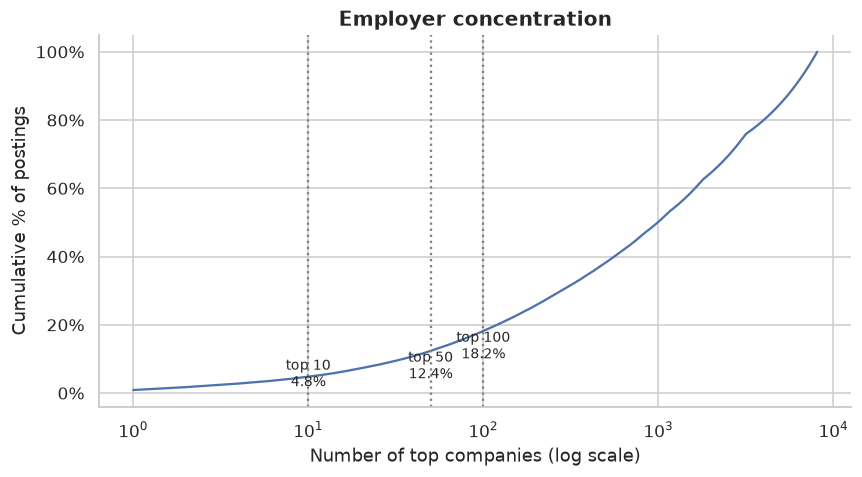

In [33]:
cum = comp_shares.cumsum().to_numpy()
xs = np.arange(1, len(cum) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, cum)
ax.set_xscale("log")
for k in (10, 50, 100):
    if k <= len(cum):
        ax.axvline(k, color="gray", ls=":")
        ax.text(k, max(cum[k - 1] - 8, 2), f"top {k}\n{cum[k - 1]:.1f}%", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter())
ax.set(title="Employer concentration", xlabel="Number of top companies (log scale)", ylabel="Cumulative % of postings")
plt.tight_layout()
plt.show()

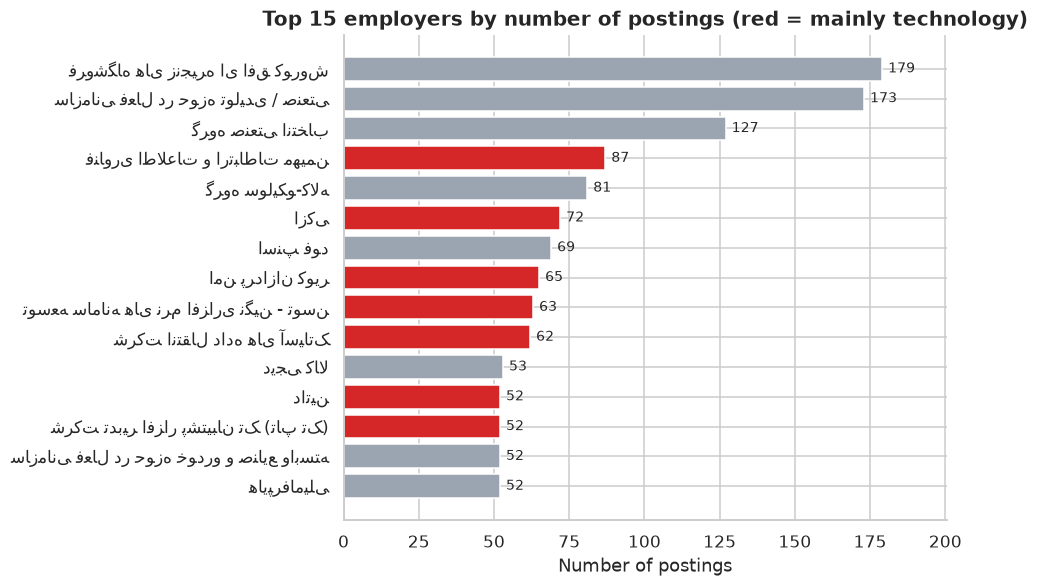

In [34]:
top_n = 15
top_companies = comp_counts.head(top_n)
dominant_sector = (df[df["company"].isin(top_companies.index)].groupby("company")["sector"].agg(lambda s: s.mode().iat[0]).reindex(top_companies.index))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(rtl_labels(top_companies.index[::-1]), top_companies.values[::-1], color=[TECH_COLOR if s == "Technology" else OTHER_COLOR for s in dominant_sector.values[::-1]])
ax.margins(x=0.12)
annotate_bars(ax)
ax.set(title=f"Top {top_n} employers by number of postings (red = mainly technology)", xlabel="Number of postings")
plt.tight_layout()
plt.show()

*Multi-valued fields (industries, skills, benefits) are split on commas outside parentheses; a name that itself contains a comma may appear as two entries.*

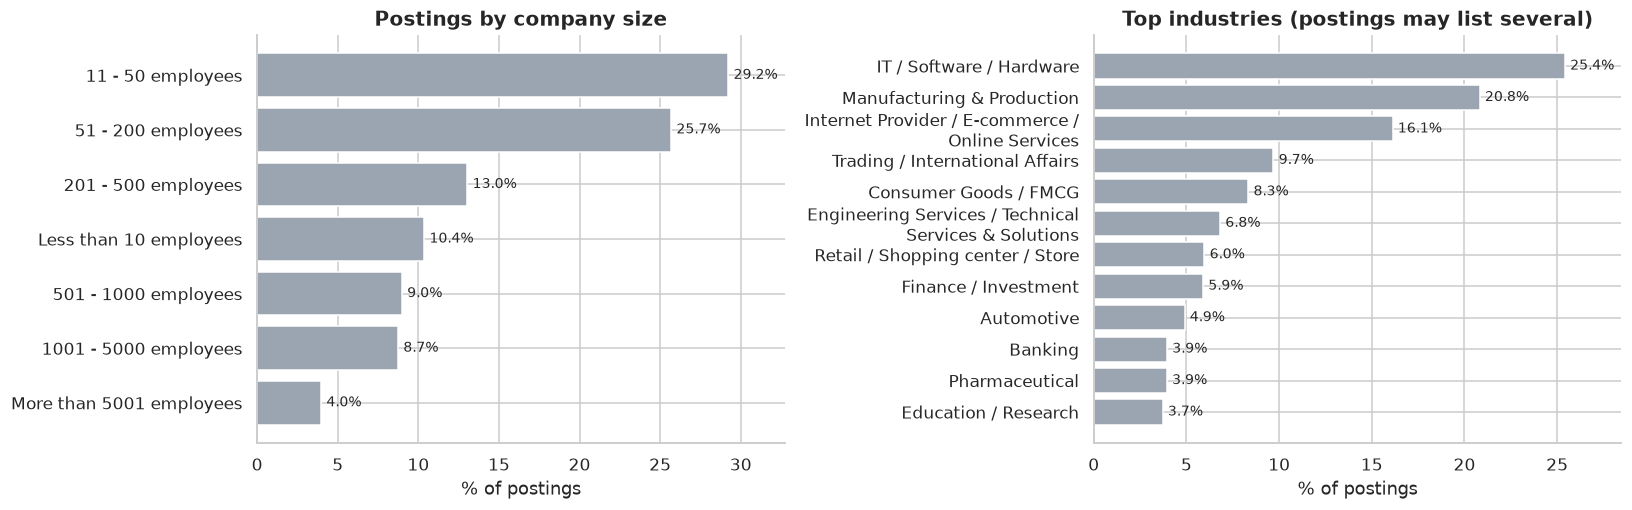

In [35]:
size_share = df["company_size"].value_counts(normalize=True) * 100
ind_items = explode_items(df["industries"], name="industry")
ind_share = ind_items["industry"].value_counts().head(12) / n_post * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].barh(size_share.index[::-1], size_share.values[::-1], color=OTHER_COLOR)
axes[0].margins(x=0.12)
annotate_bars(axes[0], "{:.1f}%")
axes[0].set(title="Postings by company size", xlabel="% of postings")
axes[1].barh([textwrap.fill(i, 34) for i in ind_share.index[::-1]], ind_share.values[::-1], color=OTHER_COLOR)
axes[1].margins(x=0.12)
annotate_bars(axes[1], "{:.1f}%")
axes[1].set(title="Top industries (postings may list several)", xlabel="% of postings")
plt.tight_layout()
plt.show()

The market is fragmented across employers: 8,073 companies posted 20,386 jobs, 61% of companies posted exactly one job, and the ten most active employers account for only 4.8% of postings (top 100: 18.2%). Employer HHI is 6.8 (≈ 1,475 equally sized employers), far below the 1,500 threshold for concentration. The leading employer, فروشگاه های زنجیره ای افق کوروش, holds 0.88% of postings. No single company can distort sector-level conclusions, although a few high-volume recruiters (chains, staffing firms) can be visible in specific niches.

### Geographic concentration
- What share of postings sits in the top province and in the top five?
- Is technology more or less centralised than other sectors?

Postings without a province: 30 | provinces represented: 31


,postings,share_%,cumulative_%
province,,,
تهران,13954,68.55,68.55
اصفهان,1093,5.37,73.92
البرز,891,4.38,78.30
خراسان رضوی,880,4.32,82.62
مازندران,460,2.26,84.88
فارس,368,1.81,86.69
قم,323,1.59,88.27
گیلان,240,1.18,89.45
خوزستان,231,1.13,90.59


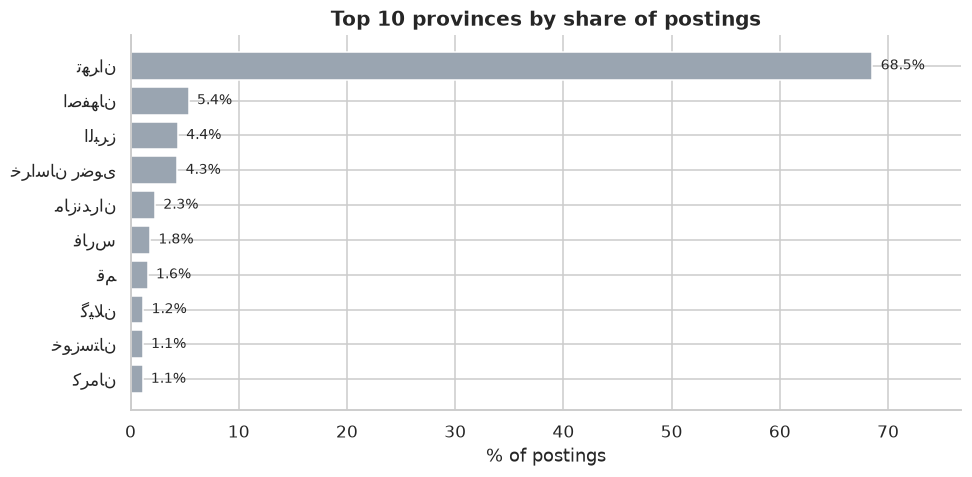

In [36]:
geo = df.dropna(subset=["province"]).copy()
prov_counts = geo["province"].value_counts()
prov_conc = concentration_metrics(prov_counts)
prov_tbl = pd.DataFrame({
    "postings": prov_counts,
    "share_%": prov_counts / prov_counts.sum() * 100,
})
prov_tbl["cumulative_%"] = prov_tbl["share_%"].cumsum()
print(f"Postings without a province: {n_post - len(geo):,} | provinces represented: {len(prov_counts)}")
display(prov_tbl.head(10).round(2))

plot = prov_tbl.head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(rtl_labels(plot.index[::-1]), plot["share_%"].values[::-1], color=OTHER_COLOR)
ax.margins(x=0.12)
annotate_bars(ax, "{:.1f}%")
ax.set(title="Top 10 provinces by share of postings", xlabel="% of postings")
plt.tight_layout()
plt.show()

In [37]:
top_prov = prov_counts.index[0]
geo["in_top_province"] = geo["province"].eq(top_prov)
top5 = set(prov_counts.index[:5])
geo["in_top5"] = geo["province"].isin(top5)

rows = []
for label, mask in (("Technology", geo["is_tech"]), ("Other sectors", ~geo["is_tech"])):
    k, n = int(geo.loc[mask, "in_top_province"].sum()), int(mask.sum())
    lo, hi = wilson_ci(k, n)
    rows.append({"group": label, "postings": n, "top_province_%": k / n * 100,
                 "ci_low": lo * 100, "ci_high": hi * 100, "top5_%": geo.loc[mask, "in_top5"].mean() * 100})
tech_geo = pd.DataFrame(rows).set_index("group")
display(tech_geo.round(1))

tab = pd.crosstab(geo["is_tech"], geo["in_top_province"])
chi2, p_geo, _, _ = stats.chi2_contingency(tab)
odds = (tab.loc[True, True] * tab.loc[False, False]) / (tab.loc[True, False] * tab.loc[False, True])

,postings,top_province_%,ci_low,ci_high,top5_%
group,,,,,
Technology,6678,75.10,74.00,76.10,88.80
Other sectors,13678,65.40,64.60,66.20,83.00


In [38]:
diff = tech_geo.loc["Technology", "top_province_%"] - tech_geo.loc["Other sectors", "top_province_%"]

The job market is heavily centralised: تهران holds 68.5% of postings and the top five provinces 84.9% (HHI ≈ 4,786). Technology is more concentrated in the top province than other sectors (75.1% vs. 65.4%, a 9.7-point gap; odds ratio 1.59, χ² p = 3.4e-44). Only 16 of 31 provinces have at least 100 postings, so regional conclusions apply to the largest labour markets only.

### How common is remote work, and who offers it?
- What share of postings are remote, and how does it differ between technology and other sectors?
- Which provinces offer the most remote roles (restricted to provinces with enough postings)?

Error bars show 95% Wilson intervals, which reflect how little a small group's rate can be trusted.

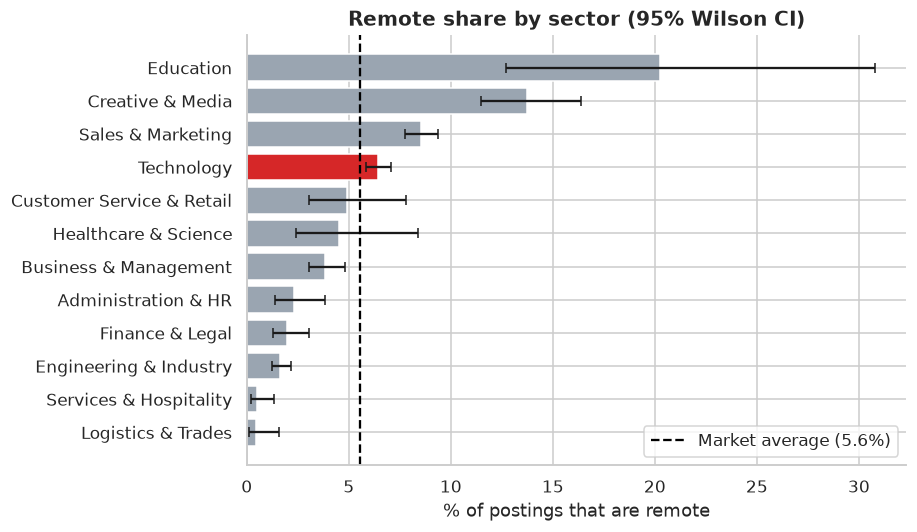

,n,k,pct,ci_low,ci_high
sector,,,,,
Education,74,15,20.30,12.70,30.80
Creative & Media,757,104,13.70,11.50,16.40
Sales & Marketing,4656,398,8.50,7.80,9.40
Technology,6686,430,6.40,5.90,7.00
Customer Service & Retail,326,16,4.90,3.00,7.80
Healthcare & Science,199,9,4.50,2.40,8.40
Business & Management,1870,72,3.90,3.10,4.80
Administration & HR,608,14,2.30,1.40,3.80
Finance & Legal,1006,20,2.00,1.30,3.10


In [39]:
remote_overall = df["remote"].mean() * 100
remote_sector = group_rate(df, "sector", "remote", MIN_GROUP)

fig, ax = plt.subplots(figsize=(8.5, 5))
r = remote_sector.iloc[::-1]
ax.barh(r.index, r["pct"], xerr=[r["pct"] - r["ci_low"], r["ci_high"] - r["pct"]], capsize=3,
        color=[TECH_COLOR if s == "Technology" else OTHER_COLOR for s in r.index])
ax.axvline(remote_overall, color="black", ls="--", label=f"Market average ({remote_overall:.1f}%)")
ax.set(title="Remote share by sector (95% Wilson CI)", xlabel="% of postings that are remote")
ax.legend()
plt.tight_layout()
plt.show()
remote_sector.round(1)

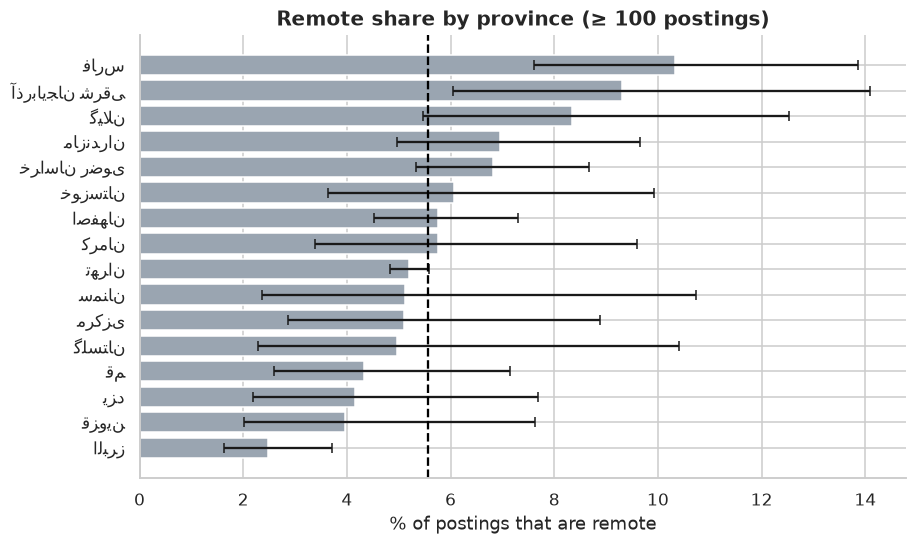

In [40]:
remote_prov = group_rate(geo, "province", "remote", MIN_PROVINCE)
fig, ax = plt.subplots(figsize=(8.5, max(3.5, 0.32 * len(remote_prov))))
r = remote_prov.iloc[::-1]
ax.barh(rtl_labels(r.index), r["pct"], xerr=[r["pct"] - r["ci_low"], r["ci_high"] - r["pct"]], capsize=3, color=OTHER_COLOR)
ax.axvline(remote_overall, color="black", ls="--")
ax.set(title=f"Remote share by province (≥ {MIN_PROVINCE} postings)", xlabel="% of postings that are remote")
plt.tight_layout()
plt.show()

tab_r = pd.crosstab(df["is_tech"], df["remote"])
chi2_r, p_r, _, _ = stats.chi2_contingency(tab_r)
or_r = (tab_r.loc[True, True] * tab_r.loc[False, False]) / (tab_r.loc[True, False] * tab_r.loc[False, True])
remote_tech = df.groupby("is_tech")["remote"].mean() * 100

Remote work is rare: 5.6% of postings. Technology offers 6.4% remote roles versus 5.1% elsewhere (odds ratio 1.27, p = 0.00016). Highest remote shares by sector: Education, Creative & Media, Sales & Marketing; the intervals show that small sectors have wide uncertainty. Among provinces with enough data, remote shares range from 2.5% to 10.3%, with overlapping intervals for most, so provincial differences should not be over-interpreted.

## Skills and Benefits

#### Which skills do employers ask for, and which are requested together?
- Which software skills are requested most often, and do technology postings ask for different ones?
- Which skill pairs co-occur more than chance would predict?
- Which benefits are advertised?

Skills here are the software requirements listed on the posting. All shares count postings mentioning the item, so they overlap and do not sum to 100%.

In [41]:
n_tech, n_other = int(df["is_tech"].sum()), int((~df["is_tech"]).sum())


def share_by_group(items: pd.DataFrame, col: str, top: int = 15) -> pd.DataFrame:
    """Share of technology / other postings mentioning each of the `top` most common items."""
    items = items.assign(is_tech=items["row"].map(df["is_tech"]))
    keep = items[col].value_counts().head(top).index
    t = (items[items[col].isin(keep)].groupby([col, "is_tech"])["row"].nunique()
         .unstack(fill_value=0).reindex(columns=[True, False], fill_value=0))
    t.columns = ["tech_n", "other_n"]
    t["overall_%"] = (t["tech_n"] + t["other_n"]) / n_post * 100
    t["tech_%"] = t["tech_n"] / n_tech * 100
    t["other_%"] = t["other_n"] / n_other * 100
    t["lift_tech_vs_other"] = t["tech_%"] / t["other_%"].replace(0, np.nan)
    return t.sort_values("overall_%", ascending=False)


sw_items = explode_items(df["software"], name="skill")
n_with_sw = sw_items["row"].nunique()
skill_tbl = share_by_group(sw_items, "skill", top=15)
print(f"Postings listing at least one skill: {n_with_sw:,} ({n_with_sw / n_post:.1%}); distinct skills: {sw_items['skill'].nunique():,}")
skill_tbl.round(2)

Postings listing at least one skill: 14,837 (72.8%); distinct skills: 454


,tech_n,other_n,overall_%,tech_%,other_%,lift_tech_vs_other
skill,,,,,,
Microsoft Excel,620,6200,33.45,9.27,45.26,0.20
Microsoft Word,444,3878,21.20,6.64,28.31,0.23
Python,1129,228,6.66,16.89,1.66,10.15
Linux,1254,33,6.31,18.76,0.24,77.86
Adobe Photoshop,74,1064,5.58,1.11,7.77,0.14
Docker,1061,13,5.27,15.87,0.09,167.23
Windows Server,857,11,4.26,12.82,0.08,159.64
Git,823,24,4.15,12.31,0.18,70.27
Microsoft Power BI,133,685,4.01,1.99,5.00,0.40


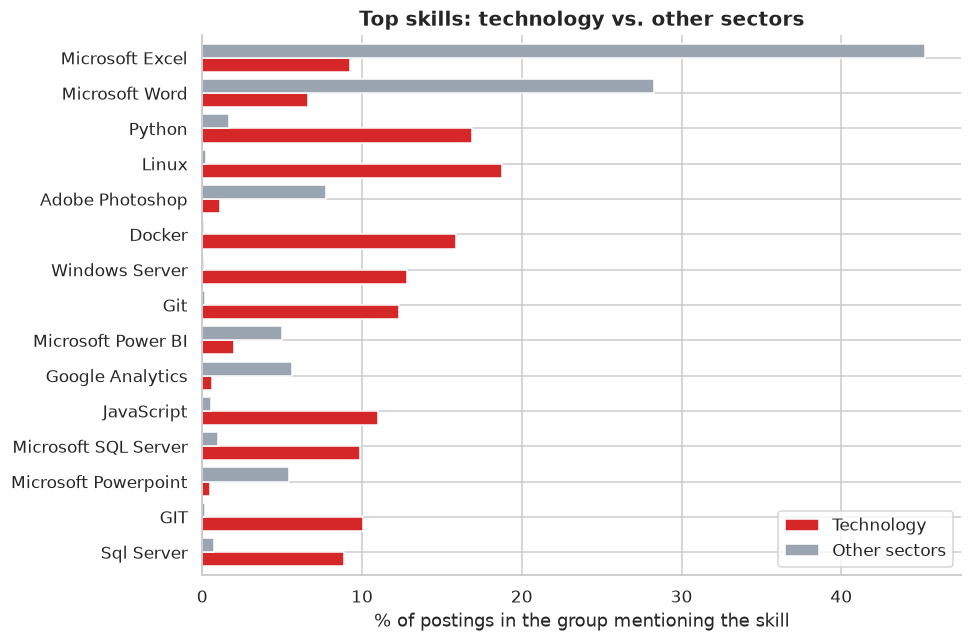

In [42]:
fig, ax = plt.subplots(figsize=(9, 6))
skill_tbl[["tech_%", "other_%"]].iloc[::-1].plot.barh(ax=ax, color=[TECH_COLOR, OTHER_COLOR], width=0.8)
ax.set(title="Top skills: technology vs. other sectors", xlabel="% of postings in the group mentioning the skill", ylabel="")
ax.legend(["Technology", "Other sectors"])
plt.tight_layout()
plt.show()

#### Skill co-occurrence
Two complementary measures describe how often two skills appear on the same posting:
- **Jaccard** = |A ∩ B| / |A ∪ B| — how interchangeable or bundled the skills are (0 to 1).
- **Lift** = P(A and B) / (P(A) · P(B)) — how much more often they co-occur than independence would predict. Computed among postings that list any skill.

Pairs with very low support are ignored because their lift is unstable.

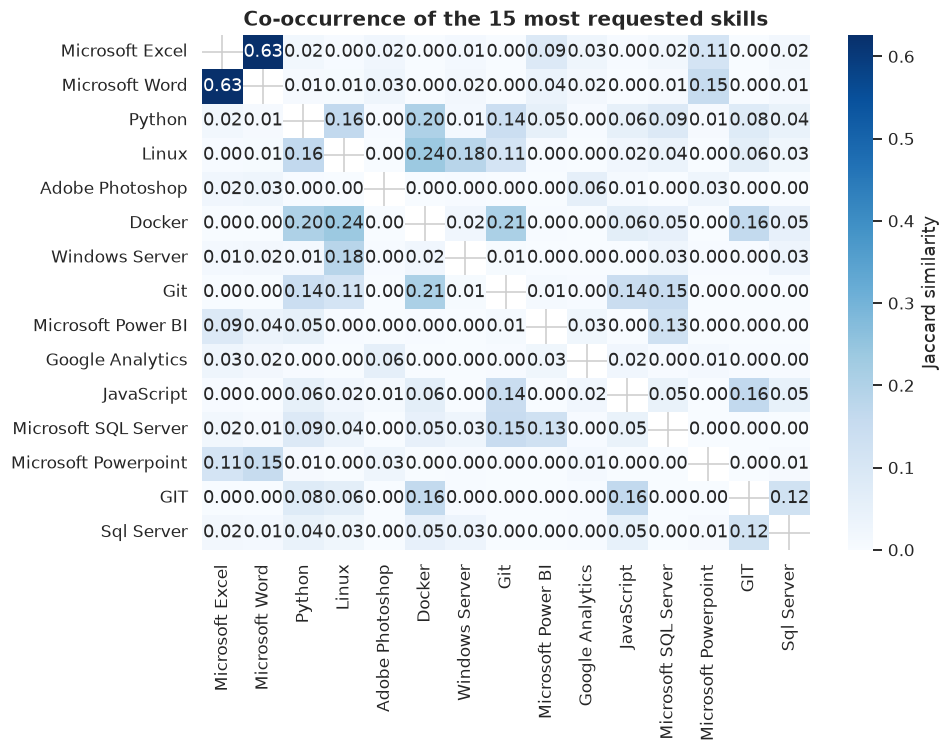

,skill_a,skill_b,postings,jaccard,lift
97,JavaScript,GIT,212,0.16,5.59
61,Docker,Git,331,0.21,5.40
40,Linux,Docker,455,0.24,4.88
67,Docker,GIT,246,0.16,4.88
80,Git,Microsoft SQL Server,214,0.15,4.72
104,GIT,Sql Server,153,0.12,4.72
79,Git,JavaScript,209,0.14,4.53
41,Linux,Windows Server,336,0.18,4.46


In [43]:
from itertools import combinations

K = 15
top_skills = skill_tbl.index.tolist()[:K]
M = pd.crosstab(sw_items["row"], sw_items["skill"]).reindex(columns=top_skills, fill_value=0).gt(0).astype(int)
co = M.T @ M
n_i = np.diag(co.to_numpy())
jac = pd.DataFrame(co.to_numpy() / (n_i[:, None] + n_i[None, :] - co.to_numpy()), index=top_skills, columns=top_skills)

MIN_SUPPORT = max(10, int(0.005 * n_with_sw))
pair_tbl = pd.DataFrame([{
    "skill_a": a, "skill_b": b, "postings": int(co.loc[a, b]),
    "jaccard": jac.loc[a, b],
    "lift": co.loc[a, b] * n_with_sw / (co.loc[a, a] * co.loc[b, b]),
} for a, b in combinations(top_skills, 2)])
pair_tbl = pair_tbl[pair_tbl["postings"] >= MIN_SUPPORT].sort_values("lift", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(jac, mask=np.eye(len(jac), dtype=bool), annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "Jaccard similarity"})
ax.set_title(f"Co-occurrence of the {K} most requested skills")
plt.tight_layout()
plt.show()
display(pair_tbl.head(8).round(3))

In [44]:
n_sk = sw_items.groupby("row").size()
mw_sk = mannwhitney_report(n_sk[n_sk.index.isin(df.index[df["is_tech"]])], n_sk[n_sk.index.isin(df.index[~df["is_tech"]])], ("tech", "other"))

ben_items = explode_items(df["benefits"], name="benefit")
ben_tbl = share_by_group(ben_items, "benefit", top=10)
display(ben_tbl.round(2))

,tech_n,other_n,overall_%,tech_%,other_%,lift_tech_vs_other
benefit,,,,,,
Health insurance,3830,6964,52.95,57.28,50.83,1.13
Occasional packages and gifts,3268,6536,48.09,48.88,47.71,1.02
Bonus,2983,6605,47.03,44.62,48.21,0.93
Loan,2580,5081,37.58,38.59,37.09,1.04
Lunch,1535,3353,23.98,22.96,24.47,0.94
Learning stipends,1547,2775,21.20,23.14,20.26,1.14
Commision,489,2768,15.98,7.31,20.20,0.36
Flexible working hours,1447,1785,15.85,21.64,13.03,1.66
Breakfast,1103,1977,15.11,16.50,14.43,1.14


In [45]:
best = pair_tbl.iloc[0] if len(pair_tbl) else None

73% of postings list at least one software skill; the most requested are Microsoft Excel, Microsoft Word, Python. Technology postings list a median of 4 skills versus 2 elsewhere (Cliff's δ = +0.45, medium). The strongest association among frequent pairs is JavaScript + GIT (lift 5.59, 212 postings), meaning they appear together 5.6× more often than chance. The most advertised benefit is Health insurance (52.9% of postings). These lists feed the multi-hot skill features of the matching stage; skills below the support threshold should be grouped before modelling.

## Salary

#### What do employers pay, and which factors are associated with higher pay?
- What share of postings disclose a salary, and do disclosers differ systematically from non-disclosers?
- What is a typical salary, and how wide are the advertised ranges?
- How does pay differ between technology and other sectors, and across experience and seniority?
- Which factors remain associated with pay after adjusting for the others?

Salaries are advertised as a *range* (`salary_min`–`salary_max`); the **midpoint** summarises each posting. Values are in **million tomans**.

In [46]:
df["salary_mid"] = ((df["salary_min"] + df["salary_max"]) / 2).where(df["salary_max"] >= df["salary_min"])
sal = df.copy()
sal["salary_disclosed"] = sal["salary_min"].notna() & sal["salary_max"].notna()
disc_rate = sal["salary_disclosed"].mean() * 100

display(pd.crosstab(sal["salary_visible"], sal["salary_disclosed"], rownames=["salary_visible flag"], colnames=["salary values present"]))

disclosure = {col: group_rate(sal, col, "salary_disclosed", MIN_GROUP) for col in ("sector", "seniority", "company_size")}
for col, t in disclosure.items():
    print(f"\nDisclosure rate by {col}")
    display(t[["n", "pct", "ci_low", "ci_high"]].round(1))

salary values present,False,True
salary_visible flag,,
False,13662,9
True,4,6711



Disclosure rate by sector


,n,pct,ci_low,ci_high
sector,,,,
Creative & Media,757,46.80,43.20,50.30
Sales & Marketing,4656,45.70,44.30,47.20
Logistics & Trades,459,37.90,33.60,42.40
Education,74,35.10,25.20,46.50
Healthcare & Science,199,34.20,27.90,41.00
Finance & Legal,1006,33.10,30.30,36.10
Customer Service & Retail,326,32.80,28.00,38.10
Administration & HR,608,32.70,29.10,36.60
Engineering & Industry,2964,28.70,27.10,30.40



Disclosure rate by seniority


,n,pct,ci_low,ci_high
seniority,,,,
Employee,1886,38.70,36.50,40.90
CEO / Business Head,56,37.50,26.00,50.60
Worker,322,36.30,31.30,41.70
Specialist,12183,35.40,34.50,36.20
Deputy / Senior Manager,206,32.50,26.50,39.20
Manager,1833,25.60,23.70,27.70
Senior Specialist,3863,25.60,24.30,27.00



Disclosure rate by company_size


,n,pct,ci_low,ci_high
company_size,,,,
Less than 10 employees,2112,52.60,50.40,54.70
11 - 50 employees,5957,49.00,47.70,50.30
51 - 200 employees,5235,32.00,30.80,33.30
201 - 500 employees,2658,18.90,17.40,20.40
501 - 1000 employees,1831,15.00,13.50,16.70
1001 - 5000 employees,1782,9.70,8.40,11.20
More than 5001 employees,809,7.90,6.20,10.00


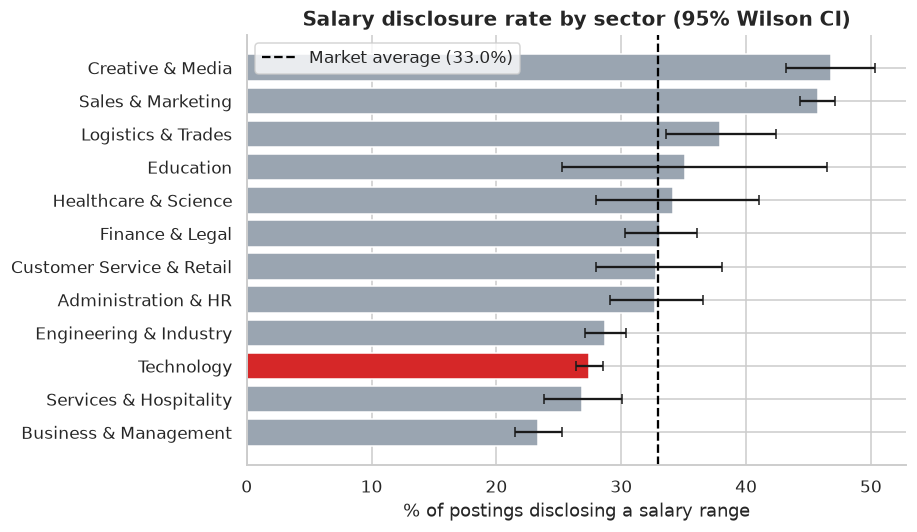

In [47]:
fig, ax = plt.subplots(figsize=(8.5, 5))
r = disclosure["sector"].iloc[::-1]
ax.barh(r.index, r["pct"], xerr=[r["pct"] - r["ci_low"], r["ci_high"] - r["pct"]], capsize=3,
        color=[TECH_COLOR if s == "Technology" else OTHER_COLOR for s in r.index])
ax.axvline(disc_rate, color="black", ls="--", label=f"Market average ({disc_rate:.1f}%)")
ax.set(title="Salary disclosure rate by sector (95% Wilson CI)", xlabel="% of postings disclosing a salary range")
ax.legend()
plt.tight_layout()
plt.show()

#### Do disclosing postings differ from the rest?
If disclosure is selective, salary statistics describe *disclosing employers*, not the market. A first check compares experience requirements,
applicant counts and technology share between postings that do and do not publish pay.

In [48]:
sel = pd.DataFrame({
    var: mannwhitney_report(sal.loc[sal["salary_disclosed"], var], sal.loc[~sal["salary_disclosed"], var], ("disclosed", "hidden"))
    for var in ("experience_years", "application_count")
}).T
sel["effect"] = sel["cliffs_delta"].map(effect_label)
display(sel[["n_disclosed", "n_hidden", "median_disclosed", "median_hidden", "p_value", "cliffs_delta", "effect"]].round(3))

tab_sel = pd.crosstab(sal["is_tech"], sal["salary_disclosed"])
p_sel = stats.chi2_contingency(tab_sel)[1]
tech_by_disc = sal.groupby("salary_disclosed")["is_tech"].mean() * 100

,n_disclosed,n_hidden,median_disclosed,median_hidden,p_value,cliffs_delta,effect
experience_years,"6,720.00","13,666.00",3.00,3.00,0.00,-0.07,negligible
application_count,"4,065.00","8,030.00",149.00,156.00,0.56,-0.01,negligible


33.0% of postings publish a salary range (the salary_visible flag agrees with the presence of salary values for 99.9% of rows). Disclosure varies by sector from 23% to 47% (Creative & Media highest). Disclosing postings are 27.3% technology versus 35.5% for non-disclosing ones (p = 9.5e-32), and differ in experience requirements by δ = -0.07 (negligible). Implication: salary findings below describe disclosing employers; extrapolating to all postings requires the assumption that disclosure is unrelated to pay level, which cannot be verified here.

#### Distribution of advertised pay

In [49]:
s = sal[sal["salary_disclosed"] & (sal["salary_max"] >= sal["salary_min"])].copy()
s["mid"] = s["salary_mid"]
s["gap"] = s["salary_max"] - s["salary_min"]
s["gap_pct"] = s["gap"] / s["salary_min"] * 100
s["ratio"] = s["salary_max"] / s["salary_min"]
s["group"] = np.where(s["is_tech"], "Technology", "Other sectors")
print(f"Postings with a valid salary range: {len(s):,}  (dropped {int(sal['salary_disclosed'].sum()) - len(s)} with max < min)")

cols = ["salary_min", "salary_max", "mid"]
desc = s[cols].describe(percentiles=[.1, .25, .5, .75, .9, .99]).T
desc["skew"] = s[cols].skew()
desc.round(2)

Postings with a valid salary range: 6,720  (dropped 0 with max < min)


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max,skew
salary_min,"6,720.00",39.54,23.08,3.00,20.00,25.00,35.00,45.00,65.00,120.00,320.00,3.51
salary_max,"6,720.00",55.29,32.58,4.00,30.00,35.00,45.00,60.00,90.00,178.10,500.00,3.61
mid,"6,720.00",47.41,27.55,3.50,25.00,30.00,40.00,55.00,75.00,150.00,400.00,3.55


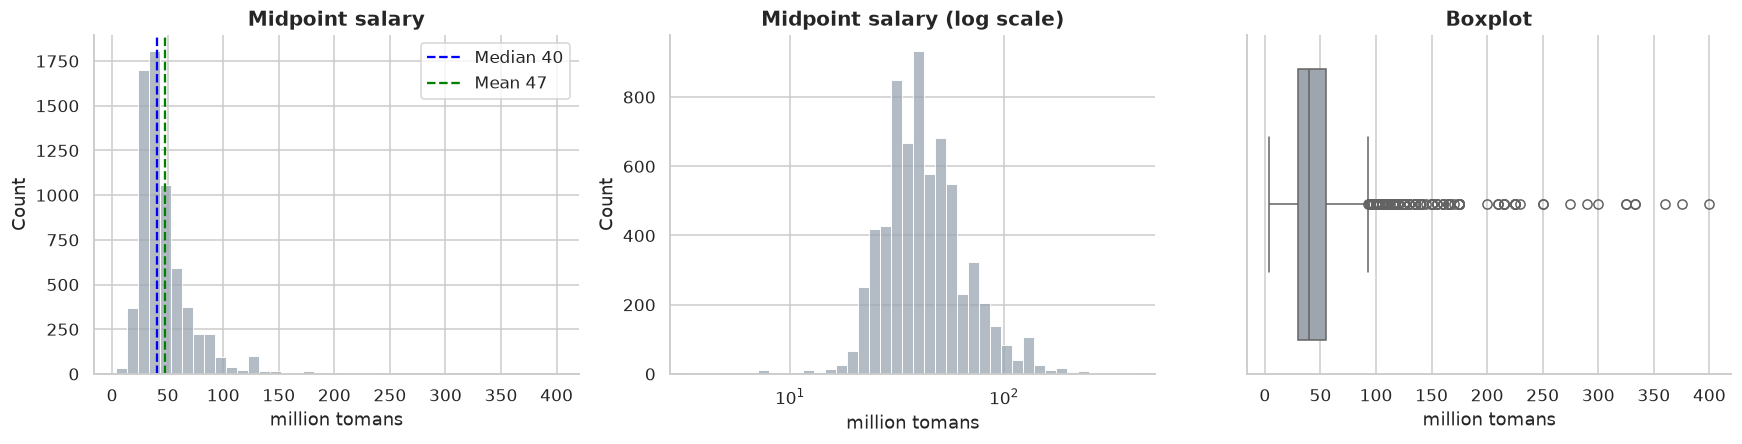

In [50]:
q1, q3 = s["mid"].quantile([.25, .75])
upper_fence = q3 + 1.5 * (q3 - q1)
n_out = int((s["mid"] > upper_fence).sum())
heaping = (s["salary_min"] % 5 == 0).mean() * 100
sal_median, sal_mean = s["mid"].median(), s["mid"].mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(s["mid"], bins=40, ax=axes[0], color=OTHER_COLOR)
axes[0].axvline(sal_median, color="blue", ls="--", label=f"Median {sal_median:.0f}")
axes[0].axvline(sal_mean, color="green", ls="--", label=f"Mean {sal_mean:.0f}")
axes[0].legend()
axes[0].set(title="Midpoint salary", xlabel=SALARY_UNIT)
sns.histplot(s["mid"], bins=40, log_scale=True, ax=axes[1], color=OTHER_COLOR)
axes[1].set(title="Midpoint salary (log scale)", xlabel=SALARY_UNIT)
sns.boxplot(x=s["mid"], ax=axes[2], color=OTHER_COLOR)
axes[2].set(title="Boxplot", xlabel=SALARY_UNIT)
plt.tight_layout()
plt.show()

#### Is pay log-normal?
Right-skewed positive data such as salaries are often modelled as log-normal. Two probability plots check this:
- **Uniform probability plot** (`pplot`) of the probability-integral transform *u = F(salary)* under a fitted log-normal. If the model is right, *u* is uniform and the points hug the diagonal.
- **Normal Q–Q plot** of log-salary. A straight line means log-salary is normal.

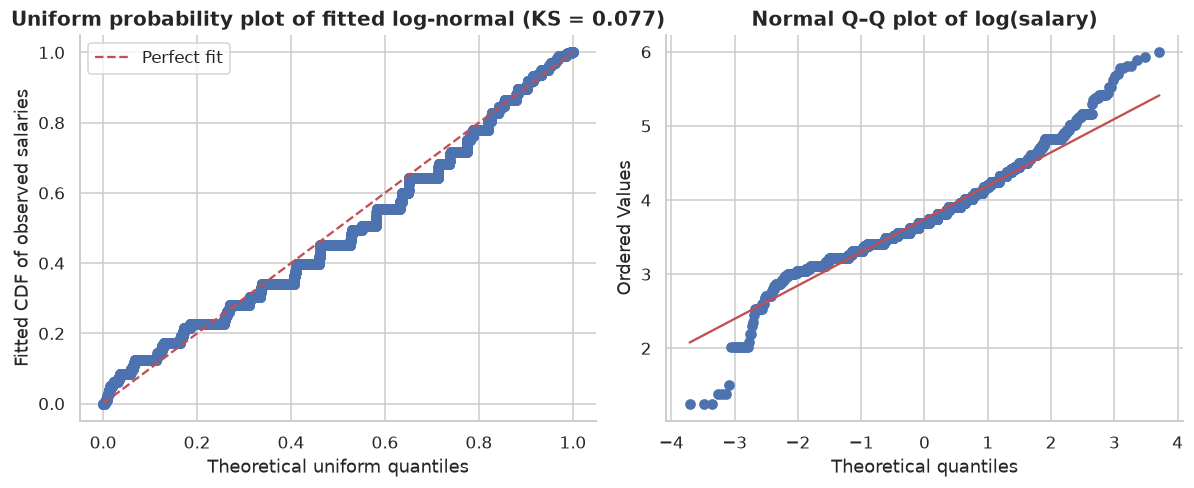

In [51]:
shape, loc, scale = stats.lognorm.fit(s["mid"], floc=0)
u = stats.lognorm.cdf(s["mid"], shape, loc=loc, scale=scale)
ks_stat = stats.kstest(u, "uniform").statistic

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
pplot(u, plot=axes[0])
axes[0].plot([0, 1], [0, 1], "r--", label="Perfect fit")
axes[0].set(title=f"Uniform probability plot of fitted log-normal (KS = {ks_stat:.3f})", xlabel="Theoretical uniform quantiles", ylabel="Fitted CDF of observed salaries")
axes[0].legend()
stats.probplot(np.log(s["mid"]), dist="norm", plot=axes[1])
axes[1].set_title("Normal Q–Q plot of log(salary)")
plt.tight_layout()
plt.show()

The typical advertised salary is 40 million tomans (median; IQR 30–55). The mean (47.4) sits above the median and skewness is 3.6, so the distribution is right-skewed; 347 postings (5.2%) exceed the upper IQR fence of 92. Medians and rank-based methods are therefore used throughout. The log-normal model is only a rough approximation (KS distance 0.077); deviations in the plots are most visible in the tails and in the steps caused by round-number advertising: 84% of lower bounds are multiples of 5 (roughly 20% would be expected by chance). Salaries are thus heaped on round values, which limits how finely differences can be resolved.

#### How wide are the advertised ranges?

In [52]:
s[["gap", "gap_pct", "ratio"]].describe(percentiles=[.25, .5, .75]).T.round(2)

,count,mean,std,min,25%,50%,75%,max
gap,"6,720.00",15.75,12.35,1.00,10.00,10.00,20.00,200.00
gap_pct,"6,720.00",41.40,21.60,1.00,25.00,40.00,50.00,100.00
ratio,"6,720.00",1.41,0.22,1.01,1.25,1.40,1.50,2.00


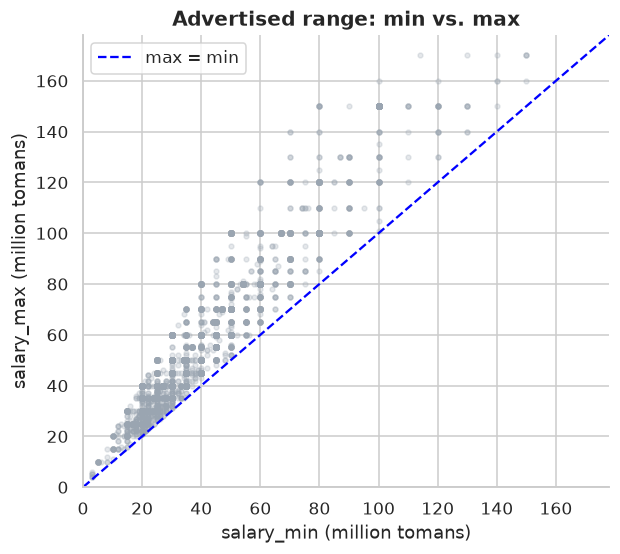

In [53]:
rho_minmax = s["salary_min"].corr(s["salary_max"], method="spearman")
rho_midgap = s["mid"].corr(s["gap"], method="spearman")

fig, ax = plt.subplots(figsize=(5.8, 5.2))
ax.scatter(s["salary_min"], s["salary_max"], alpha=0.25, s=10, color=OTHER_COLOR)
lim = s["salary_max"].quantile(.99)
ax.plot([0, lim], [0, lim], "--", color="blue", label="max = min")
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel=f"salary_min ({SALARY_UNIT})", ylabel=f"salary_max ({SALARY_UNIT})", title="Advertised range: min vs. max")
ax.legend()
plt.tight_layout()
plt.show()

The upper bound is typically 1.40× the lower bound (median range width 10 million tomans, or 40% of the lower bound). Lower and upper bounds are almost interchangeable as predictors (Spearman ρ = 0.94), while absolute range width grows with pay level (ρ(mid, gap) = 0.67). Relative width stays similar across the scale, which is why the midpoint is a sound single summary and range width adds little independent information.

#### Technology vs. other sectors

,Mann-Whitney: midpoint salary
n_tech,"1,834.00"
n_other,"4,886.00"
median_tech,42.50
median_other,40.00
U,"5,095,855.00"
p_value,0.00
prob_superiority,0.57
cliffs_delta,0.14


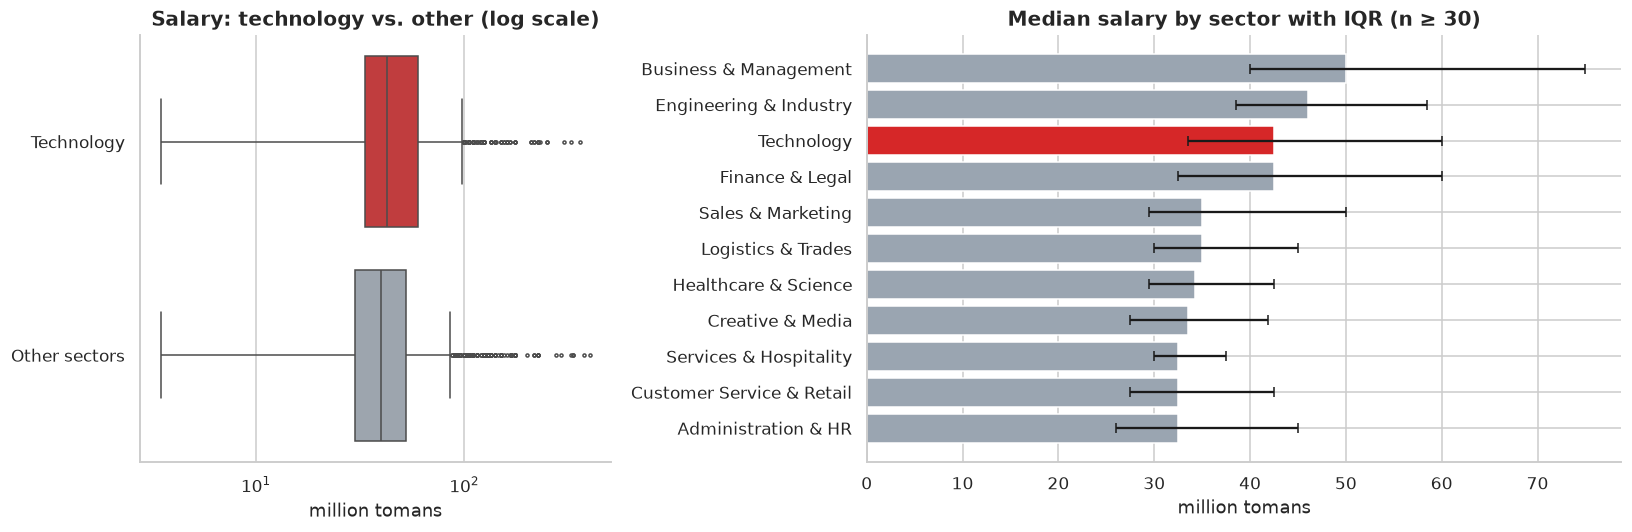

,n,median,q1,q3
sector,,,,
Business & Management,436,50.00,40.00,75.00
Engineering & Industry,851,46.00,38.50,58.50
Finance & Legal,333,42.50,32.50,60.00
Technology,1834,42.50,33.50,60.00
Logistics & Trades,174,35.00,30.00,45.00
Sales & Marketing,2129,35.00,29.50,50.00
Healthcare & Science,68,34.20,29.50,42.50
Creative & Media,354,33.50,27.50,41.90
Services & Hospitality,209,32.50,30.00,37.50


In [54]:
def boot_median_diff(a, b, n_boot=2000):
    """95% bootstrap interval for median(a) - median(b)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    diffs = [np.median(rng.choice(a, a.size)) - np.median(rng.choice(b, b.size)) for _ in range(n_boot)]
    return np.percentile(diffs, [2.5, 97.5])


mw_sal = mannwhitney_report(s.loc[s["is_tech"], "mid"], s.loc[~s["is_tech"], "mid"], ("tech", "other"))
ci_lo, ci_hi = boot_median_diff(s.loc[s["is_tech"], "mid"], s.loc[~s["is_tech"], "mid"])
display(mw_sal.to_frame("Mann-Whitney: midpoint salary").round(3))

sec_sal = (s.groupby("sector")["mid"]
           .agg(n="size", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75))
           .query("n >= @MIN_SALARY_GROUP").sort_values("median"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
sns.boxplot(data=s, x="mid", y="group", order=["Technology", "Other sectors"], hue="group",
            palette={"Technology": TECH_COLOR, "Other sectors": OTHER_COLOR}, legend=False, fliersize=2, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set(title="Salary: technology vs. other (log scale)", xlabel=SALARY_UNIT, ylabel="")
axes[1].barh(sec_sal.index, sec_sal["median"], xerr=[sec_sal["median"] - sec_sal["q1"], sec_sal["q3"] - sec_sal["median"]], capsize=3,
             color=[TECH_COLOR if x == "Technology" else OTHER_COLOR for x in sec_sal.index])
axes[1].set(title=f"Median salary by sector with IQR (n ≥ {MIN_SALARY_GROUP})", xlabel=SALARY_UNIT)
plt.tight_layout()
plt.show()
sec_sal.sort_values("median", ascending=False).round(1)

Technology postings advertise a median of 42 versus 40 million tomans elsewhere, a gap of +2 (bootstrap 95% CI +2.0 to +6.5). A randomly chosen technology posting pays more than a random non-technology posting with probability 0.57 (Cliff's δ = +0.14, negligible; p = 3.5e-18). Highest-paying sector by median: Business & Management (50); lowest: Administration & HR (32). Part of any technology gap may reflect higher experience requirements, which the adjusted model below separates out.

#### Experience and seniority

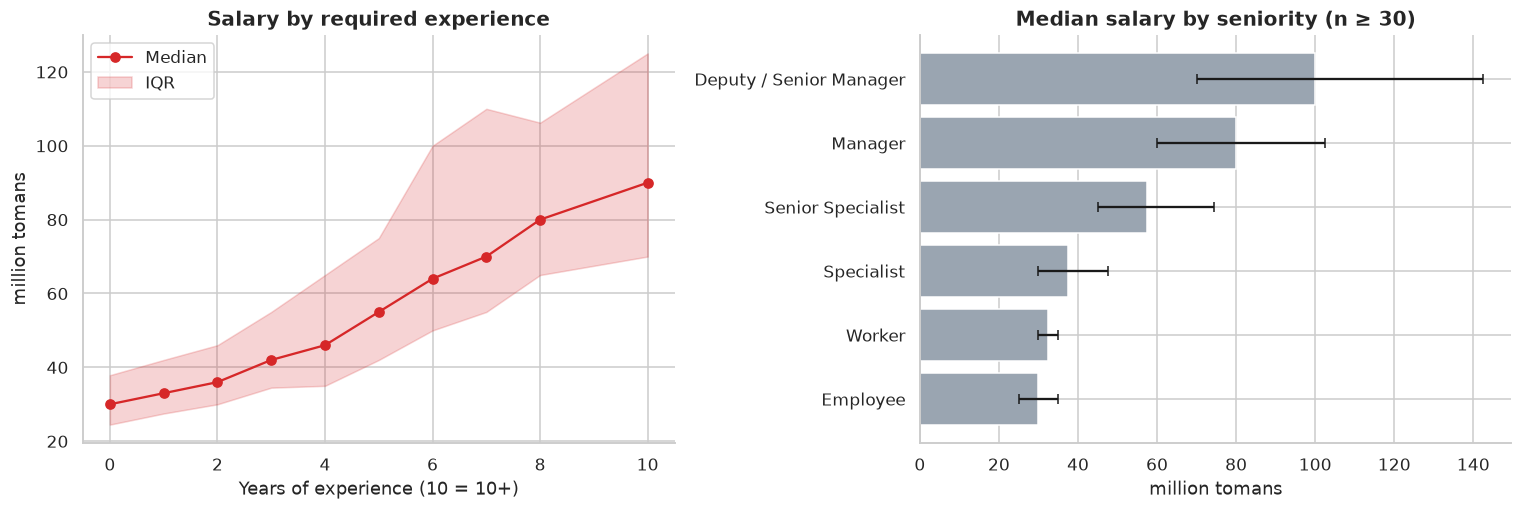

In [55]:
s["exp_bin"] = s["experience_years"].clip(upper=10)
exp_sal = (s.groupby("exp_bin")["mid"].agg(n="size", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)).query("n >= 10"))
sen_sal = (s.groupby("seniority")["mid"].agg(n="size", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)).query("n >= @MIN_SALARY_GROUP").sort_values("median"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(exp_sal.index, exp_sal["median"], marker="o", color=TECH_COLOR, label="Median")
axes[0].fill_between(exp_sal.index, exp_sal["q1"], exp_sal["q3"], alpha=0.2, color=TECH_COLOR, label="IQR")
axes[0].set(title="Salary by required experience", xlabel="Years of experience (10 = 10+)", ylabel=SALARY_UNIT)
axes[0].legend()
axes[1].barh(sen_sal.index, sen_sal["median"], xerr=[sen_sal["median"] - sen_sal["q1"], sen_sal["q3"] - sen_sal["median"]], capsize=3, color=OTHER_COLOR)
axes[1].set(title=f"Median salary by seniority (n ≥ {MIN_SALARY_GROUP})", xlabel=SALARY_UNIT)
plt.tight_layout(); plt.show()

#### Correlation structure
Spearman correlations (rank-based, robust to skew and outliers) between the midpoint salary and numeric or binary posting attributes.
The range width is excluded because it is mechanically tied to the midpoint.

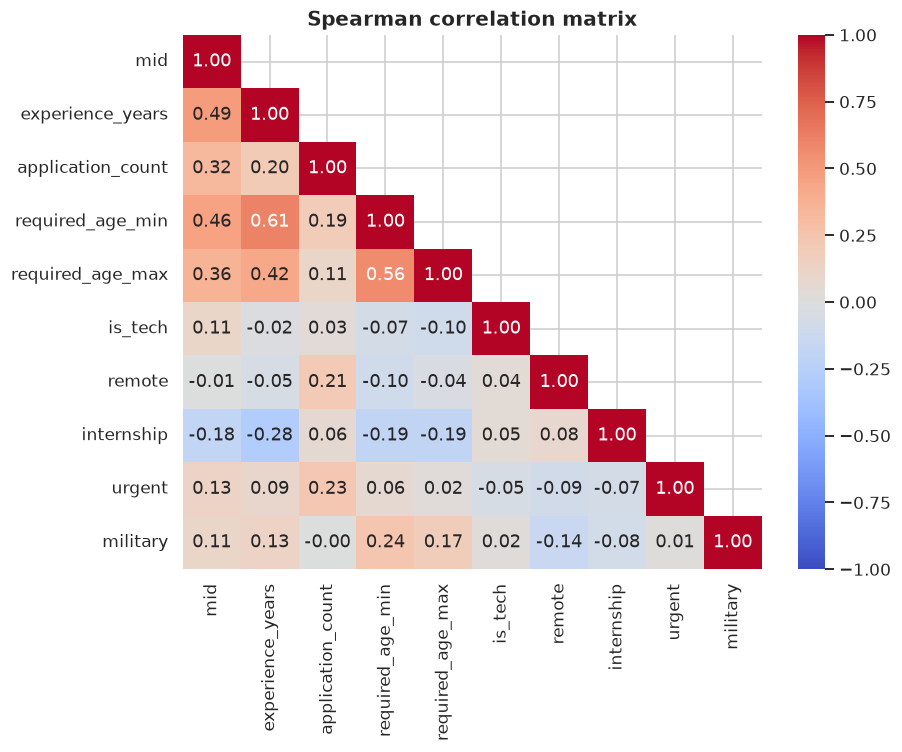

,Spearman ρ with salary
experience_years,0.49
required_age_min,0.46
required_age_max,0.36
application_count,0.32
urgent,0.13
military,0.11
is_tech,0.11
remote,-0.01
internship,-0.18


In [56]:
corr_cols = ["mid", "experience_years", "application_count", "required_age_min", "required_age_max"]
flag_cols = ["is_tech", "remote", "internship", "urgent", "military"]
cm = s[corr_cols + flag_cols].astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm, mask=np.triu(np.ones_like(cm, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation matrix")
plt.tight_layout()
plt.show()
cm["mid"].drop("mid").sort_values(ascending=False).round(3).to_frame("Spearman ρ with salary")

#### Adjusted associations
A log-linear regression estimates how each factor is associated with salary **holding the others fixed**. The outcome is `log(midpoint)`, so
`exp(β) − 1` is the approximate percentage difference. Standard errors are heteroskedasticity-robust (HC3). Because disclosure is selective
and the model omits many determinants (employer, skills, negotiation), coefficients are descriptive associations, not causal effects.

In [57]:
s["in_top_province"] = s["province"].eq(top_prov).fillna(False).astype(bool)
X = s[["experience_years", "is_tech", "remote", "urgent", "military", "in_top_province"]].astype(float)
ols = ols_hc3(np.log(s["mid"]), X)
ols["pct_difference"] = (np.exp(ols["coef"]) - 1) * 100
ols.loc["const", "pct_difference"] = np.nan
display(ols.round(3))
print(f"n = {ols.attrs['n']:,} | R² = {ols.attrs['r2']:.3f}")

,coef,robust_se,t,p_value,ci_low,ci_high,pct_difference
const,3.21,0.01,244.60,0.00,3.18,3.23,NaN
experience_years,0.11,0.00,35.97,0.00,0.10,0.12,11.80
is_tech,0.11,0.01,10.87,0.00,0.09,0.13,11.93
remote,0.07,0.02,3.07,0.00,0.03,0.11,7.14
urgent,0.07,0.01,7.61,0.00,0.05,0.09,7.57
military,0.04,0.01,3.87,0.00,0.02,0.05,3.57
in_top_province,0.21,0.01,22.37,0.00,0.19,0.23,23.57


n = 6,720 | R² = 0.333


In [58]:
e, t_ = ols.loc["experience_years"], ols.loc["is_tech"]

Controlling for the other factors, each additional required year of experience is associated with about +11.8% higher advertised pay (95% CI on the log scale +0.105 to +0.118). The technology label is associated with +11.9% (p = 2.7e-27), which is statistically distinguishable from zero after adjustment. Remote postings differ by +7.1% (p = 0.0021) and postings in تهران by +23.6% (p = 5.3e-107). The model explains R² = 0.33 of the variation in log salary: experience is the main observable driver, and most variation is left to unobserved employer-specific factors.

## Hiring Dynamics

#### How does hiring activity evolve over time?
- How many postings are activated per day or week, and is the technology share stable?
- Which weekdays see the most new postings?
- How long do postings stay live?

> **Survivorship caveat.** The data holds postings that were *active when scraped*. Postings that were activated long ago and are still
> live are, by construction, the long-running ones, so counts for earlier periods are **understated** and the series declines artificially into the past.
> Read the shape of the recent weeks and the *relative* patterns (weekday, technology share), not the absolute level of old periods.

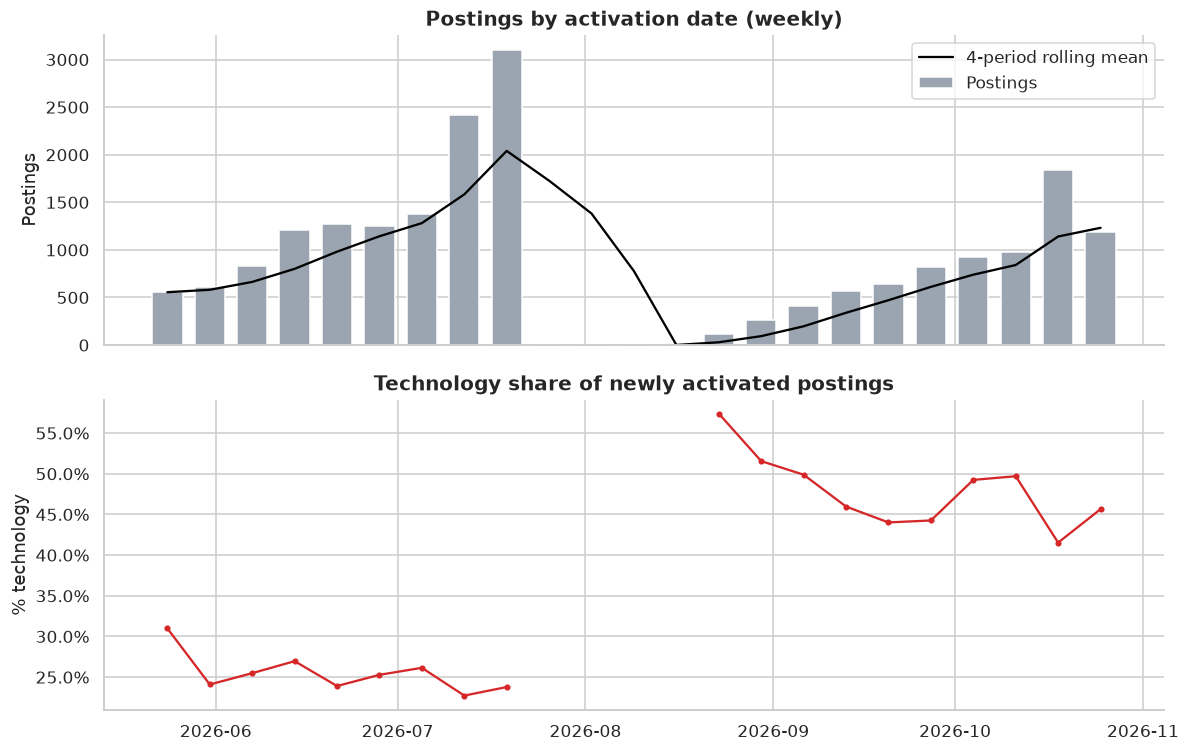

In [59]:
ts = df.dropna(subset=["activation"]).copy()
ts["act"] = ts["activation"].dt.tz_localize(None)
span_days = (ts["act"].max() - ts["act"].min()).days
FREQ = "D" if span_days < 90 else "W"
roll = 7 if FREQ == "D" else 4

counts = ts.set_index("act").resample(FREQ).size()
tech_share_ts = (ts.set_index("act")["is_tech"].resample(FREQ).mean() * 100).where(counts >= 20)  # ignore periods with too few postings

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].bar(counts.index, counts.values, width=0.8 if FREQ == "D" else 5, color=OTHER_COLOR, label="Postings")
axes[0].plot(counts.index, counts.rolling(roll, min_periods=1).mean(), color="black", label=f"{roll}-period rolling mean")
axes[0].set(title=f"Postings by activation date ({'daily' if FREQ == 'D' else 'weekly'})", ylabel="Postings")
axes[0].legend()
axes[1].plot(tech_share_ts.index, tech_share_ts.values, color=TECH_COLOR, marker="o", ms=3)
axes[1].set(title="Technology share of newly activated postings", ylabel="% technology", xlabel="")
axes[1].yaxis.set_major_formatter(PercentFormatter())
plt.tight_layout()
plt.show()

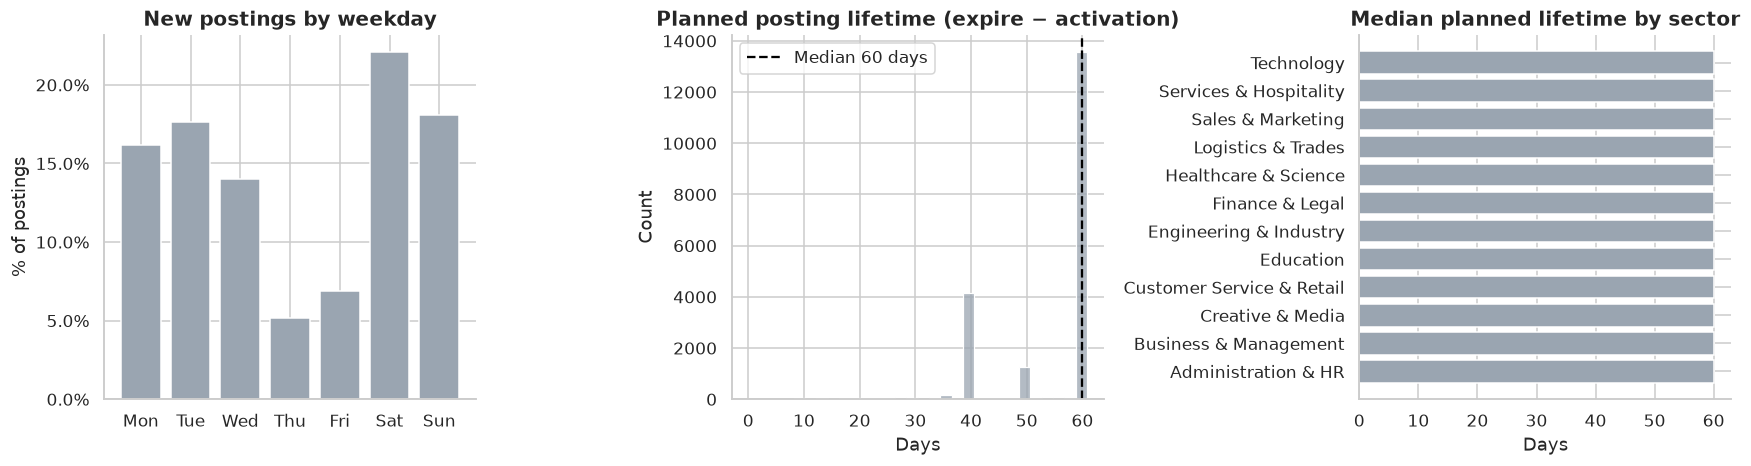

In [60]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ts["weekday"] = ts["act"].dt.day_name()
wd = ts["weekday"].value_counts(normalize=True).reindex(WEEKDAYS) * 100

ts["life_days"] = (ts["expire"] - ts["activation"]).dt.total_seconds() / 86400
life = ts["life_days"].dropna()
life_sector = (ts.groupby("sector")["life_days"].agg(n="count", median="median")
               .query("n >= @MIN_GROUP").sort_values("median"))
age_days = (ts["act"].max() - ts["act"]).dt.days

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].bar([d[:3] for d in WEEKDAYS], wd.values, color=OTHER_COLOR)
axes[0].yaxis.set_major_formatter(PercentFormatter())
axes[0].set(title="New postings by weekday", ylabel="% of postings")
sns.histplot(life, bins=30, ax=axes[1], color=OTHER_COLOR)
axes[1].axvline(life.median(), color="black", ls="--", label=f"Median {life.median():.0f} days")
axes[1].legend()
axes[1].set(title="Planned posting lifetime (expire − activation)", xlabel="Days")
axes[2].barh(life_sector.index, life_sector["median"], color=OTHER_COLOR)
axes[2].set(title="Median planned lifetime by sector", xlabel="Days")
plt.tight_layout()
plt.show()

In [61]:
busiest, quietest = wd.idxmax(), wd.idxmin()
say(f"**Reading the results.** Activation dates span **{span_days} days**; {(age_days <= 7).mean():.0%} of live postings were activated in the last week and "
    f"{(age_days <= 30).mean():.0%} in the last 30 days. "
    f"{'The window is short, so weekly or monthly trends cannot be estimated reliably.' if span_days < 28 else 'The window is long enough to see short-term trends, subject to the survivorship caveat above.'} "
    + (f"The technology share of new postings (periods with ≥ 20 postings) moves between {tech_share_ts.min():.0f}% and {tech_share_ts.max():.0f}%. " if tech_share_ts.notna().any() else "Too few postings per period to track the technology share over time. ")
    + f"{busiest} is the busiest activation day ({wd.max():.0f}% of postings) and {quietest} the quietest ({wd.min():.0f}%). "
    f"Postings are planned to stay live for a median of **{life.median():.0f} days** (IQR {life.quantile(.25):.0f}–{life.quantile(.75):.0f}), "
    f"a useful default window when generating time-aware recommendations.")

**Reading the results.** Activation dates span **159 days**; 9% of live postings were activated in the last week and 27% in the last 30 days. The window is long enough to see short-term trends, subject to the survivorship caveat above. The technology share of new postings (periods with ≥ 20 postings) moves between 23% and 57%. Saturday is the busiest activation day (22% of postings) and Thursday the quietest (5%). Postings are planned to stay live for a median of **60 days** (IQR 41–60), a useful default window when generating time-aware recommendations.

## Competition

#### Which postings attract the most applicants?
application_count is only recorded for part of the data, and older postings have had longer to collect applications. Two measures are used:
- **Applications** — the raw count.
- **Applications per day** — the count divided by days since activation (at least one day), a simple exposure adjustment.

In [62]:
snapshot = df["activation"].max()
df["age_days"] = ((snapshot - df["activation"]).dt.total_seconds() / 86400).clip(lower=1)
df["apps_per_day"] = df["application_count"] / df["age_days"]
df["salary_disclosed"] = df["salary_min"].notna() & df["salary_max"].notna()
comp = df.dropna(subset=["application_count"]).copy()

coverage = df["application_count"].notna().groupby(df["is_tech"]).mean() * 100
app = comp["application_count"]
app_desc = app.describe(percentiles=[.5, .9, .99]).to_frame("applications")
app_desc.loc["skew"] = app.skew()
display(app_desc.round(2))
print(f"Coverage: {len(comp) / n_post:.1%} of postings (technology {coverage[True]:.1f}%, other {coverage[False]:.1f}%)")

,applications
count,"12,095.00"
mean,277.30
std,317.05
min,11.00
50%,154.00
90%,704.60
99%,"1,390.12"
max,"4,675.00"
skew,2.73


Coverage: 59.3% of postings (technology 45.4%, other 66.1%)


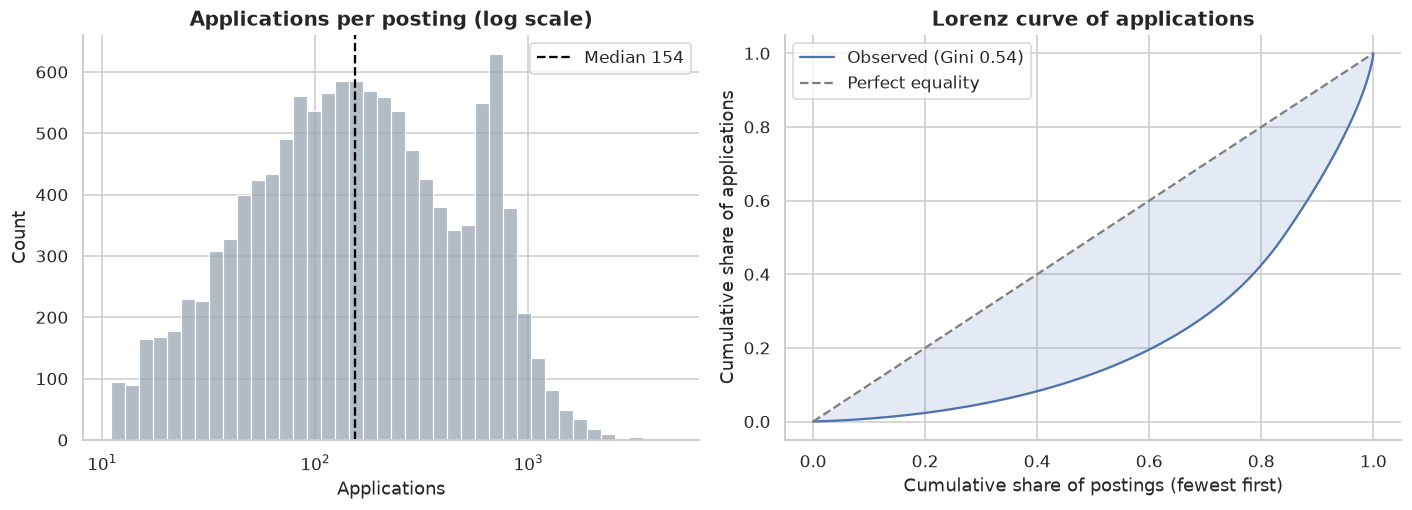

In [63]:
xl, yl = lorenz_curve(app.values)
_trapz = getattr(np, "trapezoid", None) or np.trapz
app_gini = float(1 - 2 * _trapz(yl, xl))
top10_share = app.sort_values(ascending=False).head(max(1, int(len(app) * 0.10))).sum() / app.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(app, bins=40, log_scale=True, ax=axes[0], color=OTHER_COLOR)
axes[0].axvline(app.median(), color="black", ls="--", label=f"Median {app.median():.0f}")
axes[0].legend()
axes[0].set(title="Applications per posting (log scale)", xlabel="Applications")
axes[1].plot(xl, yl, label=f"Observed (Gini {app_gini:.2f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect equality")
axes[1].fill_between(xl, yl, xl, alpha=0.15)
axes[1].set(title="Lorenz curve of applications", xlabel="Cumulative share of postings (fewest first)", ylabel="Cumulative share of applications")
axes[1].legend()
plt.tight_layout(); plt.show()

In [64]:
drivers = comp[["application_count", "apps_per_day", "age_days", "experience_years", "salary_mid"]].corr(method="spearman")
display(drivers.round(2))


def compare(mask: pd.Series, label: str) -> pd.Series:
    r = mannwhitney_report(comp.loc[mask, "apps_per_day"], comp.loc[~mask, "apps_per_day"], ("yes", "no"))
    r.name = label
    return r


cmp_tbl = pd.DataFrame([
    compare(comp["is_tech"], "Technology"),
    compare(comp["remote"], "Remote"),
    compare(comp["salary_disclosed"], "Salary disclosed"),
    compare(comp["experience_years"].le(1), "Entry-level (≤ 1 year)"),
    compare(comp["urgent"], "Marked urgent"),
])
cmp_tbl["effect"] = cmp_tbl["cliffs_delta"].map(effect_label)
cmp_tbl[["n_yes", "n_no", "median_yes", "median_no", "p_value", "cliffs_delta", "effect"]].round(3)

,application_count,apps_per_day,age_days,experience_years,salary_mid
application_count,1.00,0.99,0.19,0.15,0.32
apps_per_day,0.99,1.00,0.08,0.16,0.33
age_days,0.19,0.08,1.00,-0.03,-0.09
experience_years,0.15,0.16,-0.03,1.00,0.52
salary_mid,0.32,0.33,-0.09,0.52,1.00


,n_yes,n_no,median_yes,median_no,p_value,cliffs_delta,effect
Technology,"3,035.00","9,060.00",1.23,1.33,0.07,-0.02,negligible
Remote,726.00,"11,369.00",3.40,1.23,0.00,0.44,medium
Salary disclosed,"4,065.00","8,030.00",1.26,1.31,0.97,-0.00,negligible
Entry-level (≤ 1 year),"2,554.00","9,541.00",0.97,1.38,0.00,-0.13,negligible
Marked urgent,"6,031.00","6,064.00",1.77,0.97,0.00,0.28,small


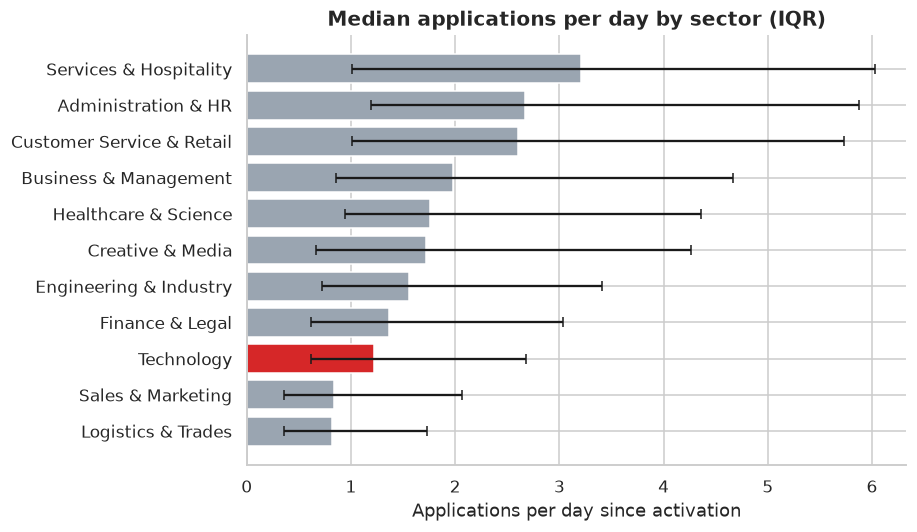

,n,median_apps,median_per_day
title,,,
مسئول دفتر,10,839.00,7.10
مدیر منابع انسانی,22,652.00,5.80
مسئول حراست - آقا,18,726.00,5.80
Front-End Developer,15,680.00,5.70
حراست - آقا,28,671.00,5.60
کارآموز دیجیتال مارکتینگ,11,598.00,5.40
مدیر مالی و حسابداری,17,634.00,5.40
کارشناس هوش مصنوعی,16,660.50,5.30
Product Manager,10,595.00,5.20


In [65]:
groups = [g["apps_per_day"].to_numpy() for _, g in comp.groupby("sector") if len(g) >= MIN_GROUP]
n_kw = sum(len(g) for g in groups)
H, p_kw = stats.kruskal(*groups)
eps2 = H * (n_kw + 1) / (n_kw**2 - 1)

sec_comp = (comp.groupby("sector")["apps_per_day"]
            .agg(n="size", median="median", q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75))
            .query("n >= @MIN_GROUP").sort_values("median"))
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(sec_comp.index, sec_comp["median"], xerr=[sec_comp["median"] - sec_comp["q1"], sec_comp["q3"] - sec_comp["median"]], capsize=3,
        color=[TECH_COLOR if x == "Technology" else OTHER_COLOR for x in sec_comp.index])
ax.set(title="Median applications per day by sector (IQR)", xlabel="Applications per day since activation")
plt.tight_layout()
plt.show()

title_tbl = (comp.groupby("title").agg(n=("job_id", "size"), median_apps=("application_count", "median"), median_per_day=("apps_per_day", "median"))
             .query("n >= 10").sort_values("median_per_day", ascending=False).head(10))
title_tbl.round(1)

Applicant counts are available for 59% of postings and are highly unequal: the median posting receives 154 applications, the 90th percentile 705, and the most-contested 10% of postings attract 36% of all applications (Gini 0.54). Raw counts are tied to posting age (ρ = 0.19), which is why applications per day is used for comparisons. Sectors differ in applicant intensity (Kruskal–Wallis p = 8.5e-175, ε² = 0.070, moderate effect); the most contested sector is Services & Hospitality (3.2 applications/day at the median). Among binary attributes, the largest effect is for Remote (δ = +0.44). Applicant counts are missing for 41% of postings, so competition results describe only postings with reported counts.

## Summary and Export

In [66]:
say(f"""### Key findings

| Theme | Finding |
|---|---|
| **Scale** | {n_post:,} unique postings from {len(comp_counts):,} companies in {len(prov_counts)} provinces |
| **Demand** | Technology is the largest sector ({tech_defs.iloc[1, 0]:.1f}% as primary sector, {tech_defs.iloc[0, 0]:.1f}% if exclusively technology). Sector HHI = {sector_conc['hhi']:,.0f} (≈ {sector_conc['effective_n']:.1f} equally sized sectors); top three sectors hold {sector_conc['top3_%']:.0f}% |
| **Entry level** | {entry_0:.1f}% of postings accept no experience; {entry_1:.1f}% accept ≤ 1 year. Technology vs. other: Cliff's δ = {mw_exp['cliffs_delta']:+.2f} ({effect_label(mw_exp['cliffs_delta'])}) |
| **Restrictions** | {rates['Any restriction']:.0f}% of postings carry at least one gender, military or age restriction |
| **Employers** | Fragmented: top 10 employers = {topk.loc[0, 'share_of_postings_%']:.1f}% of postings; {singleton_share:.0f}% of companies posted once |
| **Geography** | {top_prov} = {prov_tbl['share_%'].iloc[0]:.1f}% of postings; top five provinces = {prov_tbl['share_%'].head(5).sum():.0f}% |
| **Remote** | {remote_overall:.1f}% overall; technology {remote_tech[True]:.1f}% vs. other {remote_tech[False]:.1f}% |
| **Skills** | {n_with_sw / n_post:.0%} of postings list software skills; most common: {', '.join(skill_tbl.index[:3])} |
| **Salary** | {disc_rate:.0f}% disclose pay; median midpoint {sal_median:.0f} {SALARY_UNIT}; technology median {mw_sal['median_tech']:.0f} vs. {mw_sal['median_other']:.0f} elsewhere; +1 year experience ≈ {ols.loc['experience_years', 'pct_difference']:+.1f}% (adjusted) |
| **Timing** | Median planned posting lifetime {life.median():.0f} days; activation window {span_days} days |
| **Competition** | Median {app.median():.0f} applications per posting; top 10% of postings receive {top10_share:.0f}% of applications |
""")

### Key findings

| Theme | Finding |
|---|---|
| **Scale** | 20,386 unique postings from 8,073 companies in 31 provinces |
| **Demand** | Technology is the largest sector (32.8% as primary sector, 30.5% if exclusively technology). Sector HHI = 1,963 (≈ 5.1 equally sized sectors); top three sectors hold 70% |
| **Entry level** | 8.0% of postings accept no experience; 20.5% accept ≤ 1 year. Technology vs. other: Cliff's δ = -0.02 (negligible) |
| **Restrictions** | 82% of postings carry at least one gender, military or age restriction |
| **Employers** | Fragmented: top 10 employers = 4.8% of postings; 61% of companies posted once |
| **Geography** | تهران = 68.5% of postings; top five provinces = 85% |
| **Remote** | 5.6% overall; technology 6.4% vs. other 5.1% |
| **Skills** | 73% of postings list software skills; most common: Microsoft Excel, Microsoft Word, Python |
| **Salary** | 33% disclose pay; median midpoint 40 million tomans; technology median 42 vs. 40 elsewhere; +1 year experience ≈ +11.8% (adjusted) |
| **Timing** | Median planned posting lifetime 60 days; activation window 159 days |
| **Competition** | Median 154 applications per posting; top 10% of postings receive 36% of applications |


### Limitations
- **Selection:** keyword-based collection from one platform; non-technology results are not representative of the whole market.
- **Salary:** disclosed by a self-selected minority and heaped on round numbers; findings describe disclosing employers.
- **Time:** only postings live at scrape time are observed (survivorship); trend levels for older periods are understated.
- **Applications:** counts are partially missing and depend on posting age; per-day rates are only a first-order adjustment.
- **Taxonomy:** the primary-sector rule favours technology; hybrid postings are flagged through `n_sectors`.
- **Inference:** with thousands of rows almost any difference is statistically significant, so effect sizes are reported alongside p-values. All results are associations.

### Implications for the next stages
1. **Feature engineering** — encode `sector` / `sectors`, multi-hot encode the top skills (apply the support threshold from Section 5), use `salary_mid` only where disclosed and treat missingness as a feature.
2. **Matching engine** — combine seniority label and experience years rather than relying on either; respect hard restrictions (`military_req`, `gender_strict`, age range) as filters.
3. **Recommendation engine** — account for the heavy geographic concentration (cold-start in small provinces) and the skewed competition distribution (`apps_per_day`) when ranking.